toy eg/

In [2]:
import numpy as np

# Toy spike-count data
counts = np.array([1, 2, 0, 3, 1])

dt = 0.1  # 100 ms in seconds

# Gamma prior: shape-rate parameterization
alpha_prior = 2.0
beta_prior = 0.2

n = len(counts)
total_spikes = counts.sum()
total_time = n * dt

# Poisson MLE
lambda_mle = total_spikes / total_time

# Gamma posterior
alpha_post = alpha_prior + total_spikes
beta_post = beta_prior + total_time

# Prior and posterior means
prior_mean = alpha_prior / beta_prior
posterior_mean = alpha_post / beta_post

print(f"Number of observations : {n}")
print(f"Total spikes           : {total_spikes}")
print(f"Total exposure         : {total_time:.2f} s")
print()
print(f"Prior mean             : {prior_mean:.2f} spikes/s")
print(f"MLE estimate           : {lambda_mle:.2f} spikes/s")
print(f"Posterior alpha        : {alpha_post:.2f}")
print(f"Posterior beta         : {beta_post:.2f}")
print(f"Posterior mean         : {posterior_mean:.2f} spikes/s")

Number of observations : 5
Total spikes           : 7
Total exposure         : 0.50 s

Prior mean             : 10.00 spikes/s
MLE estimate           : 14.00 spikes/s
Posterior alpha        : 9.00
Posterior beta         : 0.70
Posterior mean         : 12.86 spikes/s


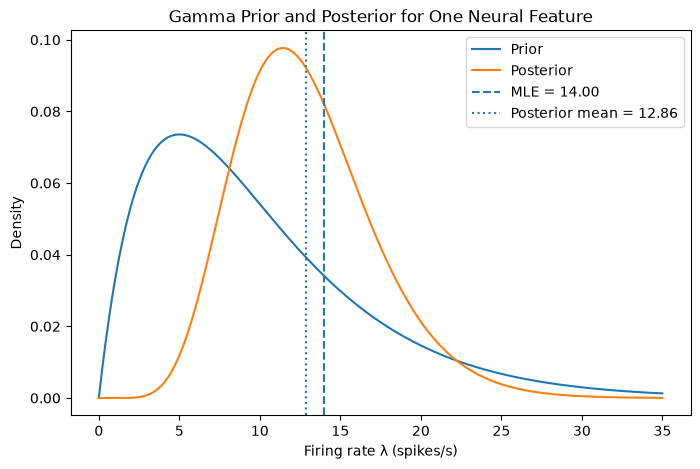

In [3]:
import matplotlib.pyplot as plt
from scipy.stats import gamma

lambda_grid = np.linspace(0, 35, 500)

# IMPORTANT:
# scipy.stats.gamma uses SCALE = 1 / rate
prior_pdf = gamma.pdf(
    lambda_grid,
    a=alpha_prior,
    scale=1 / beta_prior,
)

posterior_pdf = gamma.pdf(
    lambda_grid,
    a=alpha_post,
    scale=1 / beta_post,
)

plt.figure(figsize=(8, 5))

plt.plot(
    lambda_grid,
    prior_pdf,
    label="Prior",
)

plt.plot(
    lambda_grid,
    posterior_pdf,
    label="Posterior",
)

plt.axvline(
    lambda_mle,
    linestyle="--",
    label=f"MLE = {lambda_mle:.2f}",
)

plt.axvline(
    posterior_mean,
    linestyle=":",
    label=f"Posterior mean = {posterior_mean:.2f}",
)

plt.xlabel("Firing rate λ (spikes/s)")
plt.ylabel("Density")
plt.title("Gamma Prior and Posterior for One Neural Feature")
plt.legend()

plt.show()

In [4]:
from scipy.stats import poisson
from scipy.special import gammaln
import numpy as np

x_new = 2

# Posterior from previous example
alpha_post = 9.0
beta_post = 0.7
dt = 0.1

# -------------------------------------------------
# Level 1: posterior-mean plug-in Poisson
# -------------------------------------------------

lambda_post_mean = alpha_post / beta_post
mu_plugin = lambda_post_mean * dt

p_plugin = poisson.pmf(x_new, mu=mu_plugin)

# -------------------------------------------------
# Level 2: full Gamma-Poisson posterior predictive
# -------------------------------------------------

log_p_predictive = (
    gammaln(alpha_post + x_new)
    - gammaln(alpha_post)
    - gammaln(x_new + 1)
    + alpha_post * np.log(beta_post / (beta_post + dt))
    + x_new * np.log(dt / (beta_post + dt))
)

p_predictive = np.exp(log_p_predictive)

print(f"New spike count             : {x_new}")
print(f"Posterior mean rate         : {lambda_post_mean:.3f} spikes/s")
print()
print(f"Plug-in Poisson probability : {p_plugin:.6f}")
print(f"Gamma-Poisson predictive    : {p_predictive:.6f}")

New spike count             : 2
Posterior mean rate         : 12.857 spikes/s

Plug-in Poisson probability : 0.228497
Gamma-Poisson predictive    : 0.211400


In [5]:
import numpy as np

training_counts = {
    1: np.array([0, 1, 0, 1, 0]),
    2: np.array([1, 2, 2, 1, 2]),
    3: np.array([3, 4, 2, 4, 3]),
}

dt = 0.1

alpha_prior = 2.0
beta_prior = 0.2

posterior_params = {}

for c, counts in training_counts.items():

    total_spikes = counts.sum()
    total_time = len(counts) * dt

    alpha_post = alpha_prior + total_spikes
    beta_post = beta_prior + total_time

    posterior_mean = alpha_post / beta_post
    mle_rate = total_spikes / total_time

    posterior_params[c] = {
        "alpha": alpha_post,
        "beta": beta_post,
        "posterior_mean": posterior_mean,
        "mle_rate": mle_rate,
    }

    print(f"Class {c}")
    print(f"  total spikes       = {total_spikes}")
    print(f"  MLE rate           = {mle_rate:.2f} spikes/s")
    print(f"  posterior alpha    = {alpha_post:.2f}")
    print(f"  posterior beta     = {beta_post:.2f}")
    print(f"  posterior mean     = {posterior_mean:.2f} spikes/s")
    print()

Class 1
  total spikes       = 2
  MLE rate           = 4.00 spikes/s
  posterior alpha    = 4.00
  posterior beta     = 0.70
  posterior mean     = 5.71 spikes/s

Class 2
  total spikes       = 8
  MLE rate           = 16.00 spikes/s
  posterior alpha    = 10.00
  posterior beta     = 0.70
  posterior mean     = 14.29 spikes/s

Class 3
  total spikes       = 16
  MLE rate           = 32.00 spikes/s
  posterior alpha    = 18.00
  posterior beta     = 0.70
  posterior mean     = 25.71 spikes/s



In [6]:
from scipy.special import gammaln

x_new = 2

log_scores = {}

for c, params in posterior_params.items():

    a = params["alpha"]
    b = params["beta"]

    log_predictive = (
        gammaln(a + x_new)
        - gammaln(a)
        - gammaln(x_new + 1)
        + a * np.log(b / (b + dt))
        + x_new * np.log(dt / (b + dt))
    )

    log_scores[c] = log_predictive

    print(
        f"Class {c}: "
        f"log predictive = {log_predictive:.4f}, "
        f"predictive probability = {np.exp(log_predictive):.4f}"
    )

Class 1: log predictive = -2.3904, predictive probability = 0.0916
Class 2: log predictive = -1.4869, predictive probability = 0.2261
Class 3: log predictive = -1.4208, predictive probability = 0.2415


In [7]:
predicted_class = max(log_scores, key=log_scores.get)

print(f"Observed spike count : {x_new}")
print(f"Predicted number     : {predicted_class}")

Observed spike count : 2
Predicted number     : 3


## Multiclass Gamma–Poisson decoding

For every number class \(c\), a separate Gamma posterior is learned for each neural feature.

For feature \(j\),

\[
\lambda_{cj}\mid D
\sim
\operatorname{Gamma}
\left(
\alpha'_{cj},
\beta'_{cj}
\right).
\]

Given a new population spike-count vector

\[
\mathbf{x}
=
[x_1,\ldots,x_p],
\]

the posterior-predictive probability for each feature is calculated.

Assuming conditional independence across neural features,

\[
p(\mathbf{x}\mid c,D)
=
\prod_{j=1}^{p}
p(x_j\mid c,D).
\]

For numerical stability, calculations are performed in log space:

\[
\log p(\mathbf{x}\mid c,D)
=
\sum_{j=1}^{p}
\log p(x_j\mid c,D).
\]

Including the class prior,

\[
S_c(\mathbf{x})
=
\log p(\mathbf{x}\mid c,D)
+
\log p(c).
\]

The predicted number is

\[
\hat c
=
\arg\max_c
S_c(\mathbf{x}).
\]

For the initial analysis, a uniform class prior is used:

\[
p(c)=\frac{1}{9}.
\]

---

--

In [8]:
from pathlib import Path
import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().parent

# Neurons used for YFF
neuron_table = pd.read_csv(
    PROJECT_ROOT / "tables1" / "figure1M_YFF_permutation.csv"
)

neuron_ids = neuron_table["neuron"].astype(int).tolist()

print("Subject: YFF")
print("Number of neurons:", len(neuron_ids))
print("Neuron IDs:", neuron_ids)

Subject: YFF
Number of neurons: 37
Neuron IDs: [9, 10, 11, 12, 13, 14, 15, 16, 17, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54]


In [9]:
from pathlib import Path
import sys

# If notebook is inside notebooks1/
PROJECT_ROOT = Path.cwd().parent

# Add repository root to Python path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Notebook directory :", Path.cwd())
print("Project root       :", PROJECT_ROOT)
print("src exists         :", (PROJECT_ROOT / "src").exists())

Notebook directory : c:\Users\shafi\number-simplex-reproduction\notebooks1
Project root       : c:\Users\shafi\number-simplex-reproduction
src exists         : True


In [10]:
from src.population_level_decoding import build_population_matrix

import inspect

print(inspect.signature(build_population_matrix))


(subject, neuron_ids, root, bin_ms=100, window_start_ms=50, window_end_ms=950)


In [11]:
print(Path.cwd())

c:\Users\shafi\number-simplex-reproduction\notebooks1


In [12]:
from src.population_level_decoding import build_population_matrix

pop = build_population_matrix(
    subject="YFF",
    neuron_ids=neuron_ids,
    root=PROJECT_ROOT,
    bin_ms=100,
    window_start_ms=50,
    window_end_ms=950,
)

type(pop)


tuple

In [13]:
print(pop.keys() if isinstance(pop, dict) else type(pop))

if isinstance(pop, tuple):
    print("Number of returned objects:", len(pop))
    for i, obj in enumerate(pop):
        print(i, type(obj), getattr(obj, "shape", None))

<class 'tuple'>
Number of returned objects: 5
0 <class 'numpy.ndarray'> (109, 333)
1 <class 'numpy.ndarray'> (109,)
2 <class 'numpy.ndarray'> (109,)
3 <class 'pandas.DataFrame'> (109, 6)
4 <class 'dict'> None


In [14]:
X, y, groups, presentations, metadata = pop

print("X shape       :", X.shape)
print("y shape       :", y.shape)
print("groups shape  :", groups.shape)
print("X dtype       :", X.dtype)
print("Classes       :", np.unique(y))
print("Unique trials :", len(np.unique(groups)))

X shape       : (109, 333)
y shape       : (109,)
groups shape  : (109,)
X dtype       : int64
Classes       : [1 2 3 4 5 6 7 8 9]
Unique trials : 82


In [15]:
c = 1
j = 0

counts = X[y == c, j]

print("Number class :", c)
print("Feature      :", j)
print("Neuron       :", neuron_ids[0])
print("Time bin     : 50–150 ms")
print("Counts       :", counts)
print("Presentations:", len(counts))
print("Total spikes :", counts.sum())
print("Mean count   :", counts.mean())

Number class : 1
Feature      : 0
Neuron       : 9
Time bin     : 50–150 ms
Counts       : [1 1 2 0 0 0 0 1 1 0]
Presentations: 10
Total spikes : 6
Mean count   : 0.6


In [16]:
dt = 0.1

n = len(counts)
S = counts.sum()
total_time = n * dt

lambda_mle = S / total_time

print(f"n             = {n}")
print(f"S             = {S}")
print(f"Total time    = {total_time:.2f} s")
print(f"MLE rate      = {lambda_mle:.3f} spikes/s")

n             = 10
S             = 6
Total time    = 1.00 s
MLE rate      = 6.000 spikes/s


In [17]:
from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

train_idx, test_idx = next(
    cv.split(X, y, groups=groups)
)

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

groups_train = groups[train_idx]
groups_test = groups[test_idx]

print("Training presentations :", len(train_idx))
print("Test presentations     :", len(test_idx))

print("\nTraining trials :", len(np.unique(groups_train)))
print("Test trials     :", len(np.unique(groups_test)))

print("\nShared trials:",
      np.intersect1d(groups_train, groups_test))

Training presentations : 86
Test presentations     : 23

Training trials : 66
Test trials     : 16

Shared trials: []


In [18]:
print("Training class counts:")
for c in range(1, 10):
    print(
        f"Number {c}: "
        f"{np.sum(y_train == c)}"
    )

print("\nTest class counts:")
for c in range(1, 10):
    print(
        f"Number {c}: "
        f"{np.sum(y_test == c)}"
    )

Training class counts:
Number 1: 8
Number 2: 14
Number 3: 11
Number 4: 3
Number 5: 7
Number 6: 13
Number 7: 11
Number 8: 9
Number 9: 10

Test class counts:
Number 1: 2
Number 2: 1
Number 3: 0
Number 4: 4
Number 5: 0
Number 6: 3
Number 7: 6
Number 8: 3
Number 9: 4


In [19]:
j = 0
dt = 0.1

print("Feature:", j)
print("Neuron :", neuron_ids[0])
print("Bin    : 50–150 ms")
print()

for c in range(1, 10):
    counts_c = X_train[y_train == c, j]

    print(
        f"Number {c}: "
        f"n={len(counts_c):2d}, "
        f"spikes={counts_c.sum():2d}, "
        f"mean count={counts_c.mean():.3f}, "
        f"MLE rate={counts_c.mean()/dt:.2f} spikes/s"
    )

Feature: 0
Neuron : 9
Bin    : 50–150 ms

Number 1: n= 8, spikes= 4, mean count=0.500, MLE rate=5.00 spikes/s
Number 2: n=14, spikes= 8, mean count=0.571, MLE rate=5.71 spikes/s
Number 3: n=11, spikes= 7, mean count=0.636, MLE rate=6.36 spikes/s
Number 4: n= 3, spikes= 1, mean count=0.333, MLE rate=3.33 spikes/s
Number 5: n= 7, spikes= 2, mean count=0.286, MLE rate=2.86 spikes/s
Number 6: n=13, spikes= 3, mean count=0.231, MLE rate=2.31 spikes/s
Number 7: n=11, spikes= 3, mean count=0.273, MLE rate=2.73 spikes/s
Number 8: n= 9, spikes= 2, mean count=0.222, MLE rate=2.22 spikes/s
Number 9: n=10, spikes= 3, mean count=0.300, MLE rate=3.00 spikes/s


In [20]:
all_counts_j = X_train[:, j]

total_spikes_j = all_counts_j.sum()
total_exposure_j = len(all_counts_j) * dt

global_rate_j = total_spikes_j / total_exposure_j

print("Training presentations :", len(all_counts_j))
print("Total spikes           :", total_spikes_j)
print(f"Total exposure         : {total_exposure_j:.2f} s")
print(f"Overall rate           : {global_rate_j:.3f} spikes/s")

Training presentations : 86
Total spikes           : 33
Total exposure         : 8.60 s
Overall rate           : 3.837 spikes/s


In [21]:
j = 0
dt = 0.1

# Overall training rate for this feature
global_rate_j = X_train[:, j].sum() / (len(X_train) * dt)

tau_values = [0.1, 0.5, 1.0, 5.0]

print(f"Global training rate = {global_rate_j:.3f} spikes/s\n")

for c in range(1, 10):

    counts_c = X_train[y_train == c, j]

    n_c = len(counts_c)
    S_c = counts_c.sum()

    mle_rate = S_c / (n_c * dt)

    print(f"Number {c}")
    print(f"  MLE = {mle_rate:.3f} spikes/s")

    for tau in tau_values:

        alpha_prior = global_rate_j * tau
        beta_prior = tau

        alpha_post = alpha_prior + S_c
        beta_post = beta_prior + n_c * dt

        posterior_mean = alpha_post / beta_post

        print(
            f"  tau={tau:3.1f}s -> "
            f"posterior mean={posterior_mean:.3f}"
        )

    print()

Global training rate = 3.837 spikes/s

Number 1
  MLE = 5.000 spikes/s
  tau=0.1s -> posterior mean=4.871
  tau=0.5s -> posterior mean=4.553
  tau=1.0s -> posterior mean=4.354
  tau=5.0s -> posterior mean=3.998

Number 2
  MLE = 5.714 spikes/s
  tau=0.1s -> posterior mean=5.589
  tau=0.5s -> posterior mean=5.220
  tau=1.0s -> posterior mean=4.932
  tau=5.0s -> posterior mean=4.248

Number 3
  MLE = 6.364 spikes/s
  tau=0.1s -> posterior mean=6.153
  tau=0.5s -> posterior mean=5.574
  tau=1.0s -> posterior mean=5.161
  tau=5.0s -> posterior mean=4.293

Number 4
  MLE = 3.333 spikes/s
  tau=0.1s -> posterior mean=3.459
  tau=0.5s -> posterior mean=3.648
  tau=1.0s -> posterior mean=3.721
  tau=5.0s -> posterior mean=3.809

Number 5
  MLE = 2.857 spikes/s
  tau=0.1s -> posterior mean=2.980
  tau=0.5s -> posterior mean=3.266
  tau=1.0s -> posterior mean=3.434
  tau=5.0s -> posterior mean=3.717

Number 6
  MLE = 2.308 spikes/s
  tau=0.1s -> posterior mean=2.417
  tau=0.5s -> posterior mean=

In [22]:
tau = 0.1
dt = 0.1

n_classes = 9
n_features = X_train.shape[1]

alpha_prior = np.zeros(n_features)
beta_prior = np.full(n_features, tau)

alpha_post = np.zeros((n_classes, n_features))
beta_post = np.zeros((n_classes, n_features))
posterior_mean = np.zeros((n_classes, n_features))

In [23]:
# Overall training firing rate for every feature
global_rates = (
    X_train.sum(axis=0)
    /
    (len(X_train) * dt)
)

alpha_prior = global_rates * tau

In [24]:
for c in range(1, 10):

    class_mask = y_train == c
    X_c = X_train[class_mask]

    n_c = X_c.shape[0]

    # Total spikes for each of the 333 features
    S_c = X_c.sum(axis=0)

    alpha_post[c - 1] = alpha_prior + S_c

    beta_post[c - 1] = (
        beta_prior + n_c * dt
    )

    posterior_mean[c - 1] = (
        alpha_post[c - 1]
        /
        beta_post[c - 1]
    )

print("alpha_post shape    :", alpha_post.shape)
print("beta_post shape     :", beta_post.shape)
print("posterior_mean shape:", posterior_mean.shape)

alpha_post shape    : (9, 333)
beta_post shape     : (9, 333)
posterior_mean shape: (9, 333)


In [25]:
tau = 0.1
dt = 0.1

n_classes = 9
n_features = X_train.shape[1]

# ---------------------------------------
# 1. Feature-specific prior
# ---------------------------------------

global_rates = (
    X_train.sum(axis=0)
    / (len(X_train) * dt)
)

alpha_prior = global_rates * tau
beta_prior = np.full(n_features, tau)

# ---------------------------------------
# 2. Storage for class-specific posteriors
# ---------------------------------------

alpha_post = np.zeros((n_classes, n_features))
beta_post = np.zeros((n_classes, n_features))
posterior_mean = np.zeros((n_classes, n_features))

# ---------------------------------------
# 3. Fit posterior for each number
# ---------------------------------------

for c in range(1, 10):

    X_c = X_train[y_train == c]

    n_c = X_c.shape[0]
    S_c = X_c.sum(axis=0)

    alpha_post[c - 1] = alpha_prior + S_c
    beta_post[c - 1] = beta_prior + n_c * dt

    posterior_mean[c - 1] = (
        alpha_post[c - 1]
        / beta_post[c - 1]
    )

print("Prior alpha shape    :", alpha_prior.shape)
print("Prior beta shape     :", beta_prior.shape)

print("Posterior alpha shape:", alpha_post.shape)
print("Posterior beta shape :", beta_post.shape)
print("Posterior mean shape :", posterior_mean.shape)

Prior alpha shape    : (333,)
Prior beta shape     : (333,)
Posterior alpha shape: (9, 333)
Posterior beta shape : (9, 333)
Posterior mean shape : (9, 333)


In [26]:
zero_global_features = np.where(global_rates == 0)[0]

print(
    "Features with zero spikes across training:",
    len(zero_global_features)
)

print(
    "First few indices:",
    zero_global_features[:20]
)

Features with zero spikes across training: 4
First few indices: [ 92 110 259 328]


In [27]:
zero_global_features = np.where(global_rates == 0)[0]

print("Total features:", len(global_rates))
print("Zero-rate features:", len(zero_global_features))
print("Nonzero features:", np.sum(global_rates > 0))

if len(zero_global_features) > 0:
    print("Zero-rate feature indices:")
    print(zero_global_features)

Total features: 333
Zero-rate features: 4
Nonzero features: 329
Zero-rate feature indices:
[ 92 110 259 328]


In [28]:
# Keep only features that contain at least one spike
# somewhere in the TRAINING data
active_features = global_rates > 0

X_train_active = X_train[:, active_features]
X_test_active = X_test[:, active_features]

print("Original features :", X_train.shape[1])
print("Active features   :", X_train_active.shape[1])
print("Removed features  :", np.sum(~active_features))

Original features : 333
Active features   : 329
Removed features  : 4


In [29]:
dt = 0.1
tau = 0.1

# Global training rate for each active feature
global_rates_active = (
    X_train_active.sum(axis=0)
    / (len(X_train_active) * dt)
)

# Gamma prior: shape-rate parameterization
alpha_prior = global_rates_active * tau
beta_prior = np.full(
    X_train_active.shape[1],
    tau
)

# Storage
alpha_post = np.zeros((9, X_train_active.shape[1]))
beta_post = np.zeros((9, X_train_active.shape[1]))
posterior_mean = np.zeros((9, X_train_active.shape[1]))

for c in range(1, 10):

    X_c = X_train_active[y_train == c]

    n_c = X_c.shape[0]
    S_c = X_c.sum(axis=0)

    alpha_post[c - 1] = alpha_prior + S_c
    beta_post[c - 1] = beta_prior + n_c * dt

    posterior_mean[c - 1] = (
        alpha_post[c - 1]
        / beta_post[c - 1]
    )

print("alpha_post    :", alpha_post.shape)
print("beta_post     :", beta_post.shape)
print("posterior_mean:", posterior_mean.shape)

print("\nMinimum prior alpha:", alpha_prior.min())
print("All alpha > 0:", np.all(alpha_prior > 0))

alpha_post    : (9, 329)
beta_post     : (9, 329)
posterior_mean: (9, 329)

Minimum prior alpha: 0.011627906976744186
All alpha > 0: True


In [30]:
x_test = X_test_active[0]
true_number = y_test[0]

print("True number:", true_number)
print("Feature vector shape:", x_test.shape)
print("Total spikes in presentation:", x_test.sum())
print("Nonzero features:", np.count_nonzero(x_test))

True number: 9
Feature vector shape: (329,)
Total spikes in presentation: 408
Nonzero features: 180


In [31]:
from scipy.special import gammaln

def gamma_poisson_log_predictive(x, a, b, dt=0.1):
    
    log_prob = (
        gammaln(a + x)
        - gammaln(a)
        - gammaln(x + 1)
        + a * np.log(b / (b + dt))
        + x * np.log(dt / (b + dt))
    )
    
    return log_prob

In [32]:
class_scores = []

for c in range(1, 10):

    a = alpha_post[c - 1]
    b = beta_post[c - 1]

    feature_log_probs = gamma_poisson_log_predictive(
        x_test,
        a,
        b,
        dt=dt
    )

    log_likelihood = feature_log_probs.sum()

    # Uniform class prior
    log_prior = np.log(1 / 9)

    score = log_likelihood + log_prior

    class_scores.append(score)

class_scores = np.array(class_scores)

for c, score in enumerate(class_scores, start=1):
    print(f"Number {c}: {score:.3f}")

Number 1: -421.964
Number 2: -411.164
Number 3: -431.167
Number 4: -444.372
Number 5: -410.735
Number 6: -416.716
Number 7: -414.926
Number 8: -427.304
Number 9: -425.700


In [33]:
predicted_number = np.argmax(class_scores) + 1

print()
print("True number     :", true_number)
print("Predicted number:", predicted_number)


True number     : 9
Predicted number: 5


In [34]:
y_pred = []

for x_test in X_test_active:

    class_scores = []

    for c in range(1, 10):

        a = alpha_post[c - 1]
        b = beta_post[c - 1]

        feature_log_probs = gamma_poisson_log_predictive(
            x_test,
            a,
            b,
            dt=dt
        )

        log_likelihood = feature_log_probs.sum()

        # Uniform prior over numbers
        log_prior = np.log(1 / 9)

        score = log_likelihood + log_prior

        class_scores.append(score)

    predicted_number = np.argmax(class_scores) + 1
    y_pred.append(predicted_number)

y_pred = np.array(y_pred)

In [35]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Correct : {(y_test == y_pred).sum()} / {len(y_test)}")

Accuracy: 0.0435
Accuracy: 4.35%
Correct : 1 / 23


In [36]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from scipy.special import gammaln

dt = 0.1
tau = 0.1

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Every presentation will eventually receive one
# out-of-sample prediction
y_pred_cv = np.zeros_like(y)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups=groups),
    start=1
):

    X_tr = X[train_idx]
    X_te = X[test_idx]

    y_tr = y[train_idx]
    y_te = y[test_idx]

    # -----------------------------------------
    # 1. Training-only active feature selection
    # -----------------------------------------

    active = X_tr.sum(axis=0) > 0

    X_tr = X_tr[:, active]
    X_te = X_te[:, active]

    # -----------------------------------------
    # 2. Training-only empirical Gamma prior
    # -----------------------------------------

    global_rates = (
        X_tr.sum(axis=0)
        / (len(X_tr) * dt)
    )

    alpha_prior = global_rates * tau
    beta_prior = np.full(X_tr.shape[1], tau)

    # -----------------------------------------
    # 3. Fit class-specific Gamma posteriors
    # -----------------------------------------

    alpha_post_fold = np.zeros((9, X_tr.shape[1]))
    beta_post_fold = np.zeros((9, X_tr.shape[1]))

    for c in range(1, 10):

        X_c = X_tr[y_tr == c]

        n_c = len(X_c)
        S_c = X_c.sum(axis=0)

        alpha_post_fold[c - 1] = (
            alpha_prior + S_c
        )

        beta_post_fold[c - 1] = (
            beta_prior + n_c * dt
        )

    # -----------------------------------------
    # 4. Predict held-out presentations
    # -----------------------------------------

    fold_predictions = []

    for x in X_te:

        scores = []

        for c in range(9):

            a = alpha_post_fold[c]
            b = beta_post_fold[c]

            feature_log_prob = (
                gammaln(a + x)
                - gammaln(a)
                - gammaln(x + 1)
                + a * np.log(b / (b + dt))
                + x * np.log(dt / (b + dt))
            )

            # Uniform P(c) = 1/9
            score = (
                feature_log_prob.sum()
                + np.log(1 / 9)
            )

            scores.append(score)

        fold_predictions.append(
            np.argmax(scores) + 1
        )

    fold_predictions = np.array(fold_predictions)

    # Put predictions back into their
    # original presentation positions
    y_pred_cv[test_idx] = fold_predictions

    fold_acc = accuracy_score(
        y_te,
        fold_predictions
    )

    fold_results.append(
        {
            "fold": fold,
            "n_test": len(test_idx),
            "n_active_features": active.sum(),
            "accuracy": fold_acc
        }
    )

    print(
        f"Fold {fold}: "
        f"{fold_acc * 100:.2f}% "
        f"({(y_te == fold_predictions).sum()}"
        f"/{len(y_te)}) | "
        f"{active.sum()} active features"
    )

Fold 1: 4.35% (1/23) | 329 active features
Fold 2: 13.64% (3/22) | 328 active features
Fold 3: 19.05% (4/21) | 330 active features
Fold 4: 13.64% (3/22) | 330 active features
Fold 5: 9.52% (2/21) | 329 active features


In [37]:
overall_accuracy = accuracy_score(
    y,
    y_pred_cv
)

overall_balanced_accuracy = balanced_accuracy_score(
    y,
    y_pred_cv
)

print()
print("YFF Gamma–Poisson")
print("------------------")
print(
    f"Accuracy          : "
    f"{overall_accuracy * 100:.2f}%"
)
print(
    f"Balanced accuracy : "
    f"{overall_balanced_accuracy * 100:.2f}%"
)
print(
    f"Correct           : "
    f"{(y == y_pred_cv).sum()} / {len(y)}"
)
print(
    f"Nominal chance    : "
    f"{100/9:.2f}%"
)


YFF Gamma–Poisson
------------------
Accuracy          : 11.93%
Balanced accuracy : 9.62%
Correct           : 13 / 109
Nominal chance    : 11.11%


In [38]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(
    y,
    y_pred_cv,
    labels=np.arange(1, 10)
)

cm_df = pd.DataFrame(
    cm,
    index=[f"True {c}" for c in range(1, 10)],
    columns=[f"Pred {c}" for c in range(1, 10)]
)

display(cm_df)

,Pred 1,Pred 2,Pred 3,Pred 4,Pred 5,Pred 6,Pred 7,Pred 8,Pred 9
True 1,1,2,0,0,1,0,4,0,2
True 2,2,3,1,1,0,1,1,4,2
True 3,0,1,0,0,0,2,3,3,2
True 4,2,2,0,0,0,1,0,0,2
True 5,0,0,1,0,0,2,3,0,1
True 6,0,2,3,1,2,3,3,2,0
True 7,2,3,1,0,1,1,4,1,4
True 8,1,1,2,1,1,2,2,0,2
True 9,2,1,1,1,1,1,4,1,2


In [39]:
print("True class counts:")
for c in range(1, 10):
    print(
        f"{c}: {np.sum(y == c):2d}"
    )

print("\nPredicted class counts:")
for c in range(1, 10):
    print(
        f"{c}: {np.sum(y_pred_cv == c):2d}"
    )

True class counts:
1: 10
2: 15
3: 11
4:  7
5:  7
6: 16
7: 17
8: 12
9: 14

Predicted class counts:
1: 10
2: 15
3:  9
4:  4
5:  6
6: 13
7: 24
8: 11
9: 17


In [40]:
import numpy as np
import pandas as pd

from pathlib import Path
import sys

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from scipy.special import gammaln

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.population_level_decoding import build_population_matrix

print(PROJECT_ROOT)

c:\Users\shafi\number-simplex-reproduction


In [41]:
subject = "YFF"

per_neuron = pd.read_csv(
    PROJECT_ROOT / "tables1" / f"figure1M_{subject}_permutation.csv"
)

neuron_ids = per_neuron["neuron"].astype(int).tolist()

X, y, groups, presentations, metadata = build_population_matrix(
    subject=subject,
    neuron_ids=neuron_ids,
    root=PROJECT_ROOT,
    bin_ms=100,
    window_start_ms=50,
    window_end_ms=950,
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("unique numbers:", np.unique(y))
print("unique trials:", len(np.unique(groups)))

X shape: (109, 333)
y shape: (109,)
unique numbers: [1 2 3 4 5 6 7 8 9]
unique trials: 82


In [42]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(cv.split(X, y, groups=groups))

X_train = X[train_idx]
X_test  = X[test_idx]

y_train = y[train_idx]
y_test  = y[test_idx]

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

print("\nTraining class counts:")
print(pd.Series(y_train).value_counts().sort_index())

Training shape: (86, 333)
Test shape: (23, 333)

Training class counts:
1     8
2    14
3    11
4     3
5     7
6    13
7    11
8     9
9    10
Name: count, dtype: int64


In [43]:
dt = 0.1  # 100 ms = 0.1 seconds

N_train = len(X_train)

m = X_train.sum(axis=0) / (N_train * dt)

print("m shape:", m.shape)
print("First 10 global MLE rates:")
print(m[:10])

m shape: (333,)
First 10 global MLE rates:
[ 3.8372093   3.95348837  3.60465116  3.25581395  4.30232558  4.06976744
  5.46511628  5.          3.72093023 17.09302326]


In [44]:
beta = 0.1

alpha = m * beta

print("alpha shape:", alpha.shape)
print("beta:", beta)

print("\nFirst 10 alpha values:")
print(alpha[:10])

print("\nCheck prior mean alpha / beta:")
print((alpha / beta)[:10])

print("\nOriginal global MLE m:")
print(m[:10])


alpha shape: (333,)
beta: 0.1

First 10 alpha values:
[0.38372093 0.39534884 0.36046512 0.3255814  0.43023256 0.40697674
 0.54651163 0.5        0.37209302 1.70930233]

Check prior mean alpha / beta:
[ 3.8372093   3.95348837  3.60465116  3.25581395  4.30232558  4.06976744
  5.46511628  5.          3.72093023 17.09302326]

Original global MLE m:
[ 3.8372093   3.95348837  3.60465116  3.25581395  4.30232558  4.06976744
  5.46511628  5.          3.72093023 17.09302326]


In [45]:
classes = np.arange(1, 10)
n_features = X_train.shape[1]

alpha_post = np.zeros((9, n_features))
beta_post = np.zeros((9, n_features))
lambda_post = np.zeros((9, n_features))

for k in classes:

    # Training presentations belonging to number k
    X_k = X_train[y_train == k]

    # Number of training presentations for number k
    n_k = len(X_k)

    # Total spikes for each of the 333 features
    S_k = X_k.sum(axis=0)

    # Gamma posterior parameters
    alpha_star = alpha + S_k
    beta_star = beta + n_k * dt

    # Posterior mean firing rate
    lambda_star = alpha_star / beta_star

    alpha_post[k - 1, :] = alpha_star
    beta_post[k - 1, :] = beta_star
    lambda_post[k - 1, :] = lambda_star


print("alpha_post shape:", alpha_post.shape)
print("beta_post shape:", beta_post.shape)
print("lambda_post shape:", lambda_post.shape)

alpha_post shape: (9, 333)
beta_post shape: (9, 333)
lambda_post shape: (9, 333)


In [46]:
x_test = X_test[0]
true_class = y_test[0]

print("x_test shape:", x_test.shape)
print("True number:", true_class)
print("First 10 spike counts:", x_test[:10])

x_test shape: (333,)
True number: 9
First 10 spike counts: [0 0 0 0 0 0 0 0 0 3]


In [47]:
class_scores = np.zeros(9)

for k in range(9):

    a = alpha_post[k]
    b = beta_post[k]

    log_predictive = (
        gammaln(a + x_test)
        - gammaln(a)
        - gammaln(x_test + 1)
        + a * np.log(b / (b + dt))
        + x_test * np.log(dt / (b + dt))
    )

    # Sum over all 333 features
    log_likelihood = log_predictive.sum()

    # Uniform class prior P(Y=k) = 1/9
    log_prior = np.log(1 / 9)

    class_scores[k] = log_likelihood + log_prior


print("Class scores:")
for k, score in enumerate(class_scores, start=1):
    print(f"Number {k}: {score:.3f}")

predicted_class = np.argmax(class_scores) + 1

print("\nTrue number:     ", true_class)
print("Predicted number:", predicted_class)

Class scores:
Number 1: nan
Number 2: nan
Number 3: nan
Number 4: nan
Number 5: nan
Number 6: nan
Number 7: nan
Number 8: nan
Number 9: nan

True number:      9
Predicted number: 1


C:\Users\shafi\AppData\Local\Temp\ipykernel_7756\3159820938.py:9: RuntimeWarning: invalid value encountered in subtract
  gammaln(a + x_test)


In [48]:
print("Number of zero global rates:", np.sum(m == 0))
print("Indices:", np.where(m == 0)[0])

print("\nNumber of zero prior alphas:", np.sum(alpha == 0))

print("\nZeros in alpha_post by class:")
for k in range(9):
    print(
        f"Number {k+1}:",
        np.sum(alpha_post[k] == 0)
    )

Number of zero global rates: 4
Indices: [ 92 110 259 328]

Number of zero prior alphas: 4

Zeros in alpha_post by class:
Number 1: 4
Number 2: 4
Number 3: 4
Number 4: 4
Number 5: 4
Number 6: 4
Number 7: 4
Number 8: 4
Number 9: 4


In [49]:
epsilon = 0.01  # spikes/second

# Global pooled MLE
m = X_train.sum(axis=0) / (len(X_train) * dt)

# Positive floor only for zero/very-small global rates
m_prior = np.maximum(m, epsilon)

# Gamma prior
beta = 0.1
alpha = m_prior * beta

print("Number of exact-zero MLE rates:", np.sum(m == 0))
print("Number replaced by floor:", np.sum(m < epsilon))
print("Minimum original MLE:", m.min())
print("Minimum prior rate:", m_prior.min())
print("Minimum alpha:", alpha.min())
print("All alpha > 0:", np.all(alpha > 0))

Number of exact-zero MLE rates: 4
Number replaced by floor: 4
Minimum original MLE: 0.0
Minimum prior rate: 0.01
Minimum alpha: 0.001
All alpha > 0: True


---------

In [50]:
import numpy as np
import pandas as pd

from pathlib import Path

import sys

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix
from scipy.special import gammaln

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.population_level_decoding import build_population_matrix

print("Project root:", PROJECT_ROOT)

Project root: c:\Users\shafi\number-simplex-reproduction


In [51]:
subject = "YFF"

per_neuron = pd.read_csv(
    PROJECT_ROOT / "tables1" / f"figure1M_{subject}_permutation.csv"
)

neuron_ids = per_neuron["neuron"].astype(int).tolist()

X, y, groups, presentations, metadata = build_population_matrix(
    subject=subject,
    neuron_ids=neuron_ids,
    root=PROJECT_ROOT,
    bin_ms=100,
    window_start_ms=50,
    window_end_ms=950,
)

print("Subject:", subject)
print("Neurons:", len(neuron_ids))
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique numbers:", np.unique(y))
print("Unique trials:", len(np.unique(groups)))

Subject: YFF
Neurons: 37
X shape: (109, 333)
y shape: (109,)
Unique numbers: [1 2 3 4 5 6 7 8 9]
Unique trials: 82


In [52]:
dt = 0.1       # 100-ms bin = 0.1 seconds
beta = 0.1     # Gamma prior rate / prior exposure
epsilon = 0.01 # minimum prior firing rate, spikes/second

classes = np.arange(1, 10)

print("dt:", dt, "seconds")
print("beta:", beta)
print("epsilon:", epsilon, "spikes/second")

dt: 0.1 seconds
beta: 0.1
epsilon: 0.01 spikes/second


In [53]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(cv.split(X, y, groups=groups))

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

groups_train = groups[train_idx]
groups_test = groups[test_idx]

print("Training:", X_train.shape)
print("Test:", X_test.shape)

print("\nTraining class counts:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nShared trials between train/test:",
      len(set(groups_train) & set(groups_test)))

Training: (86, 333)
Test: (23, 333)

Training class counts:
1     8
2    14
3    11
4     3
5     7
6    13
7    11
8     9
9    10
Name: count, dtype: int64

Shared trials between train/test: 0


In [54]:
m_mle = (
    X_train.sum(axis=0)
    / (len(X_train) * dt)
)

print("Global MLE shape:", m_mle.shape)
print("First 10 global MLE rates:")
print(m_mle[:10])

print("\nZero global MLE features:",
      np.sum(m_mle == 0))

Global MLE shape: (333,)
First 10 global MLE rates:
[ 3.8372093   3.95348837  3.60465116  3.25581395  4.30232558  4.06976744
  5.46511628  5.          3.72093023 17.09302326]

Zero global MLE features: 4


In [55]:
m_prior = np.maximum(m_mle, epsilon)

print("Number of exact-zero MLE rates:",
      np.sum(m_mle == 0))

print("Number replaced by floor:",
      np.sum(m_mle < epsilon))

print("Minimum original MLE:",
      m_mle.min())

print("Minimum prior rate:",
      m_prior.min())

Number of exact-zero MLE rates: 4
Number replaced by floor: 4
Minimum original MLE: 0.0
Minimum prior rate: 0.01


In [56]:
alpha = m_prior * beta

print("alpha shape:", alpha.shape)
print("beta:", beta)

print("Minimum alpha:", alpha.min())
print("All alpha > 0:", np.all(alpha > 0))

print("\nCheck prior mean:")
print("alpha / beta:")
print((alpha / beta)[:10])

print("\nm_prior:")
print(m_prior[:10])

alpha shape: (333,)
beta: 0.1
Minimum alpha: 0.001
All alpha > 0: True

Check prior mean:
alpha / beta:
[ 3.8372093   3.95348837  3.60465116  3.25581395  4.30232558  4.06976744
  5.46511628  5.          3.72093023 17.09302326]

m_prior:
[ 3.8372093   3.95348837  3.60465116  3.25581395  4.30232558  4.06976744
  5.46511628  5.          3.72093023 17.09302326]


In [57]:
n_features = X_train.shape[1]

alpha_post = np.zeros((9, n_features))
beta_post = np.zeros((9, n_features))
lambda_post = np.zeros((9, n_features))

for k in classes:

    X_k = X_train[y_train == k]

    n_k = len(X_k)
    S_k = X_k.sum(axis=0)

    alpha_star = alpha + S_k
    beta_star = beta + n_k * dt

    lambda_star = alpha_star / beta_star

    alpha_post[k - 1, :] = alpha_star
    beta_post[k - 1, :] = beta_star
    lambda_post[k - 1, :] = lambda_star


print("alpha_post:", alpha_post.shape)
print("beta_post:", beta_post.shape)
print("lambda_post:", lambda_post.shape)

print("\nAll posterior alphas positive:",
      np.all(alpha_post > 0))

print("All posterior rates finite:",
      np.all(np.isfinite(lambda_post)))

alpha_post: (9, 333)
beta_post: (9, 333)
lambda_post: (9, 333)

All posterior alphas positive: True
All posterior rates finite: True


In [58]:
x_test = X_test[0]
true_class = y_test[0]

print("Test vector shape:", x_test.shape)
print("True number:", true_class)
print("First 10 spike counts:", x_test[:10])

Test vector shape: (333,)
True number: 9
First 10 spike counts: [0 0 0 0 0 0 0 0 0 3]


In [59]:
class_scores = np.zeros(9)

for k in range(9):

    a = alpha_post[k]
    b = beta_post[k]

    log_predictive = (
        gammaln(a + x_test)
        - gammaln(a)
        - gammaln(x_test + 1)
        + a * np.log(b / (b + dt))
        + x_test * np.log(dt / (b + dt))
    )

    log_likelihood = log_predictive.sum()

    # Uniform class prior
    log_class_prior = np.log(1 / 9)

    class_scores[k] = log_likelihood + log_class_prior


predicted_class = np.argmax(class_scores) + 1

for k, score in enumerate(class_scores, start=1):
    print(f"Number {k}: {score:.3f}")

print("\nTrue number:     ", true_class)
print("Predicted number:", predicted_class)

Number 1: -421.964
Number 2: -411.164
Number 3: -431.167
Number 4: -444.372
Number 5: -410.736
Number 6: -416.717
Number 7: -414.926
Number 8: -427.305
Number 9: -425.701

True number:      9
Predicted number: 5


In [60]:
y_pred = []

for x_test in X_test:

    class_scores = np.zeros(9)

    for k in range(9):

        a = alpha_post[k]
        b = beta_post[k]

        log_predictive = (
            gammaln(a + x_test)
            - gammaln(a)
            - gammaln(x_test + 1)
            + a * np.log(b / (b + dt))
            + x_test * np.log(dt / (b + dt))
        )

        log_likelihood = log_predictive.sum()

        # Uniform class prior
        log_class_prior = np.log(1 / 9)

        class_scores[k] = log_likelihood + log_class_prior

    predicted_class = np.argmax(class_scores) + 1

    y_pred.append(predicted_class)

y_pred = np.array(y_pred)

In [61]:
fold_accuracy = accuracy_score(y_test, y_pred)
fold_balanced_accuracy = balanced_accuracy_score(y_test, y_pred)

print("Number of test presentations:", len(y_test))
print("Correct predictions:", np.sum(y_test == y_pred))

print(f"\nAccuracy: {fold_accuracy:.4f}")
print(f"Balanced accuracy: {fold_balanced_accuracy:.4f}")

print("\nTrue labels:")
print(y_test)

print("\nPredicted labels:")
print(y_pred)

Number of test presentations: 23
Correct predictions: 1

Accuracy: 0.0435
Balanced accuracy: 0.0238

True labels:
[9 6 1 8 7 4 6 7 7 9 2 4 9 7 9 1 7 4 8 6 4 8 7]

Predicted labels:
[5 5 2 5 1 1 2 2 7 1 7 1 1 1 7 5 9 2 6 2 2 1 2]


c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [62]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Every presentation will receive exactly one held-out prediction
y_pred_oof = np.zeros_like(y)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups=groups),
    start=1
):

    # --------------------------------------------------
    # 1. Training and test data
    # --------------------------------------------------

    X_train = X[train_idx]
    X_test = X[test_idx]

    y_train = y[train_idx]
    y_test = y[test_idx]


    # --------------------------------------------------
    # 2. Global pooled MLE from TRAINING DATA ONLY
    # --------------------------------------------------

    m_mle = (
        X_train.sum(axis=0)
        / (len(X_train) * dt)
    )


    # --------------------------------------------------
    # 3. Positive floor
    # --------------------------------------------------

    m_prior = np.maximum(m_mle, epsilon)


    # --------------------------------------------------
    # 4. Gamma prior
    #
    # alpha_j = m_prior_j * beta
    # --------------------------------------------------

    alpha = m_prior * beta


    # --------------------------------------------------
    # 5. Class-specific Gamma posteriors
    # --------------------------------------------------

    n_features = X_train.shape[1]

    alpha_post = np.zeros((9, n_features))
    beta_post = np.zeros((9, n_features))

    for k in classes:

        X_k = X_train[y_train == k]

        n_k = len(X_k)
        S_k = X_k.sum(axis=0)

        alpha_post[k - 1] = alpha + S_k
        beta_post[k - 1] = beta + n_k * dt


    # --------------------------------------------------
    # 6. Posterior-predictive classification
    # --------------------------------------------------

    fold_predictions = []

    for x_test in X_test:

        class_scores = np.zeros(9)

        for k in range(9):

            a = alpha_post[k]
            b = beta_post[k]

            log_predictive = (
                gammaln(a + x_test)
                - gammaln(a)
                - gammaln(x_test + 1)
                + a * np.log(b / (b + dt))
                + x_test * np.log(dt / (b + dt))
            )

            # Uniform class prior
            log_class_prior = np.log(1 / 9)

            class_scores[k] = (
                log_predictive.sum()
                + log_class_prior
            )

        predicted_class = np.argmax(class_scores) + 1

        fold_predictions.append(predicted_class)


    fold_predictions = np.array(fold_predictions)

    # Store predictions in original presentation positions
    y_pred_oof[test_idx] = fold_predictions


    # --------------------------------------------------
    # 7. Fold summary
    # --------------------------------------------------

    fold_acc = accuracy_score(
        y_test,
        fold_predictions
    )

    fold_bal_acc = balanced_accuracy_score(
        y_test,
        fold_predictions
    )

    fold_results.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "zero_mle_features": int(np.sum(m_mle == 0)),
        "accuracy": fold_acc,
        "balanced_accuracy": fold_bal_acc
    })


fold_results = pd.DataFrame(fold_results)

display(fold_results)

c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,fold,n_train,n_test,zero_mle_features,accuracy,balanced_accuracy
0,1,86,23,4,0.043478,0.023810
1,2,87,22,5,0.136364,0.156250
2,3,88,21,3,0.190476,0.250000
3,4,87,22,3,0.136364,0.135417
4,5,88,21,4,0.095238,0.064286


In [63]:
overall_accuracy = accuracy_score(
    y,
    y_pred_oof
)

overall_balanced_accuracy = balanced_accuracy_score(
    y,
    y_pred_oof
)

n_correct = np.sum(y == y_pred_oof)

print("Subject:", subject)
print("Presentations:", len(y))
print("Correct:", n_correct)

print(
    f"\nOOF accuracy: "
    f"{overall_accuracy:.4f} "
    f"({100 * overall_accuracy:.2f}%)"
)

print(
    f"OOF balanced accuracy: "
    f"{overall_balanced_accuracy:.4f} "
    f"({100 * overall_balanced_accuracy:.2f}%)"
)

print(
    f"Nominal 9-class chance: "
    f"{1/9:.4f} "
    f"({100/9:.2f}%)"
)

Subject: YFF
Presentations: 109
Correct: 13

OOF accuracy: 0.1193 (11.93%)
OOF balanced accuracy: 0.0962 (9.62%)
Nominal 9-class chance: 0.1111 (11.11%)


In [64]:
cm = confusion_matrix(
    y,
    y_pred_oof,
    labels=classes
)

cm_df = pd.DataFrame(
    cm,
    index=[f"True {k}" for k in classes],
    columns=[f"Pred {k}" for k in classes]
)

display(cm_df)

,Pred 1,Pred 2,Pred 3,Pred 4,Pred 5,Pred 6,Pred 7,Pred 8,Pred 9
True 1,1,2,0,0,1,0,4,0,2
True 2,2,3,1,1,0,1,1,4,2
True 3,0,1,0,0,0,2,3,3,2
True 4,2,2,0,0,0,1,0,0,2
True 5,0,0,1,0,0,2,3,0,1
True 6,0,2,3,1,2,3,3,2,0
True 7,2,3,1,0,1,1,4,1,4
True 8,1,1,2,1,1,2,2,0,2
True 9,2,1,1,1,1,1,4,1,2


In [65]:
# ============================================================
# GAMMA-POISSON NAIVE BAYES
# EMPIRICAL CLASS PRIOR
# ============================================================

cv_empirical = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store one held-out prediction for every presentation
y_pred_oof_empirical = np.zeros_like(y)

fold_results_empirical = []

for fold, (train_idx, test_idx) in enumerate(
    cv_empirical.split(X, y, groups=groups),
    start=1
):

    # --------------------------------------------------------
    # 1. TRAIN / TEST SPLIT
    # --------------------------------------------------------

    X_train = X[train_idx]
    X_test = X[test_idx]

    y_train = y[train_idx]
    y_test = y[test_idx]


    # --------------------------------------------------------
    # 2. GLOBAL POOLED MLE
    #    Training data only
    # --------------------------------------------------------

    m_mle = (
        X_train.sum(axis=0)
        / (len(X_train) * dt)
    )


    # --------------------------------------------------------
    # 3. POSITIVE FLOOR
    # --------------------------------------------------------

    m_prior = np.maximum(m_mle, epsilon)


    # --------------------------------------------------------
    # 4. GAMMA PRIOR
    # --------------------------------------------------------

    alpha = m_prior * beta


    # --------------------------------------------------------
    # 5. CLASS-SPECIFIC POSTERIORS
    # --------------------------------------------------------

    n_features = X_train.shape[1]

    alpha_post = np.zeros((9, n_features))
    beta_post = np.zeros((9, n_features))

    # NEW: empirical class probabilities
    class_priors = np.zeros(9)

    for k in classes:

        X_k = X_train[y_train == k]

        n_k = len(X_k)
        S_k = X_k.sum(axis=0)

        # Gamma posterior
        alpha_post[k - 1] = alpha + S_k
        beta_post[k - 1] = beta + n_k * dt

        # Empirical CLASS prior
        class_priors[k - 1] = n_k / len(y_train)


    # --------------------------------------------------------
    # 6. CLASSIFY TEST PRESENTATIONS
    # --------------------------------------------------------

    fold_predictions = []

    for x_test in X_test:

        class_scores = np.zeros(9)

        for k in range(9):

            a = alpha_post[k]
            b = beta_post[k]

            # Gamma-Poisson posterior predictive
            log_predictive = (
                gammaln(a + x_test)
                - gammaln(a)
                - gammaln(x_test + 1)
                + a * np.log(b / (b + dt))
                + x_test * np.log(dt / (b + dt))
            )

            # EMPIRICAL CLASS PRIOR
            log_class_prior = np.log(class_priors[k])

            class_scores[k] = (
                log_predictive.sum()
                + log_class_prior
            )

        predicted_class = np.argmax(class_scores) + 1

        fold_predictions.append(predicted_class)


    fold_predictions = np.array(fold_predictions)

    # Store OOF predictions
    y_pred_oof_empirical[test_idx] = fold_predictions


    # --------------------------------------------------------
    # 7. FOLD PERFORMANCE
    # --------------------------------------------------------

    fold_acc = accuracy_score(
        y_test,
        fold_predictions
    )

    fold_bal_acc = balanced_accuracy_score(
        y_test,
        fold_predictions
    )

    fold_results_empirical.append({
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "zero_mle_features": int(np.sum(m_mle == 0)),
        "accuracy": fold_acc,
        "balanced_accuracy": fold_bal_acc
    })


fold_results_empirical = pd.DataFrame(
    fold_results_empirical
)

display(fold_results_empirical)

c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,fold,n_train,n_test,zero_mle_features,accuracy,balanced_accuracy
0,1,86,23,4,0.043478,0.023810
1,2,87,22,5,0.136364,0.156250
2,3,88,21,3,0.190476,0.250000
3,4,87,22,3,0.136364,0.135417
4,5,88,21,4,0.142857,0.092857


In [66]:
empirical_accuracy = accuracy_score(
    y,
    y_pred_oof_empirical
)

empirical_balanced_accuracy = balanced_accuracy_score(
    y,
    y_pred_oof_empirical
)

empirical_correct = np.sum(
    y == y_pred_oof_empirical
)

print("Subject:", subject)
print("Class prior: EMPIRICAL")
print("Presentations:", len(y))
print("Correct:", empirical_correct)

print(
    f"\nOOF accuracy: "
    f"{empirical_accuracy:.4f} "
    f"({100 * empirical_accuracy:.2f}%)"
)

print(
    f"OOF balanced accuracy: "
    f"{empirical_balanced_accuracy:.4f} "
    f"({100 * empirical_balanced_accuracy:.2f}%)"
)

print(
    f"Nominal 9-class chance: "
    f"{1/9:.4f} "
    f"({100/9:.2f}%)"
)

Subject: YFF
Class prior: EMPIRICAL
Presentations: 109
Correct: 14

OOF accuracy: 0.1284 (12.84%)
OOF balanced accuracy: 0.1027 (10.27%)
Nominal 9-class chance: 0.1111 (11.11%)


In [67]:
# ============================================================
# FINAL POSTERIOR-MEAN LAMBDA MATRIX
# Use ALL YFF data
# For representation / geometry analysis
# NOT for cross-validated decoding accuracy
# ============================================================

dt = 0.1
beta = 0.1
epsilon = 0.01

classes = np.arange(1, 10)

# ------------------------------------------------------------
# 1. Global pooled MLE using all YFF presentations
# ------------------------------------------------------------

m_mle_full = (
    X.sum(axis=0)
    / (len(X) * dt)
)

# Positive floor
m_prior_full = np.maximum(
    m_mle_full,
    epsilon
)

# Gamma prior
alpha_full = m_prior_full * beta


# ------------------------------------------------------------
# 2. Class-specific posterior
# ------------------------------------------------------------

n_features = X.shape[1]

alpha_post_full = np.zeros((9, n_features))
beta_post_full = np.zeros((9, n_features))
lambda_matrix = np.zeros((9, n_features))

for k in classes:

    X_k = X[y == k]

    n_k = len(X_k)
    S_k = X_k.sum(axis=0)

    alpha_post_full[k - 1] = (
        alpha_full + S_k
    )

    beta_post_full[k - 1] = (
        beta + n_k * dt
    )

    lambda_matrix[k - 1] = (
        alpha_post_full[k - 1]
        / beta_post_full[k - 1]
    )


print("Lambda matrix shape:", lambda_matrix.shape)
print("All finite:", np.all(np.isfinite(lambda_matrix)))
print("Minimum lambda:", lambda_matrix.min())
print("Maximum lambda:", lambda_matrix.max())

Lambda matrix shape: (9, 333)
All finite: True
Minimum lambda: 0.0005555555555555554
Maximum lambda: 47.9243119266055


In [68]:
lambda_matrix

array([[5.79649708, 3.98665555, 5.77147623, ..., 0.95079233, 0.95913261,
        0.94245204],
       [5.23509174, 3.36582569, 3.34288991, ..., 0.65366972, 2.53440367,
        0.02293578],
       [6.14678899, 1.15443425, 4.45718654, ..., 0.0382263 , 0.04587156,
        0.03058104],
       ...,
       [2.43119266, 4.65851172, 2.41590214, ..., 0.0254842 , 0.03058104,
        0.02038736],
       [1.82780522, 2.60409315, 4.88355681, ..., 0.03528582, 0.04234298,
        0.02822865],
       [4.25076453, 4.25688073, 2.2324159 , ..., 0.03058104, 0.03669725,
        0.02446483]], shape=(9, 333))

In [69]:
lambda_df = pd.DataFrame(
    lambda_matrix,
    index=[f"number_{k}" for k in classes]
)

lambda_df.index.name = "number"

output_path = (
    PROJECT_ROOT
    / "tables1"
    / f"{subject}_gamma_poisson_lambda_matrix.csv"
)

lambda_df.to_csv(output_path)

print("Saved to:")
print(output_path)

Saved to:
c:\Users\shafi\number-simplex-reproduction\tables1\YFF_gamma_poisson_lambda_matrix.csv


In [70]:
from src.gamma_poisson_decoding import (
    analyze_all_subjects_gamma_poisson
)

subjects = [
    "YFF",
    "YFI",
    "YFJ",
    "YFK",
    "YFL",
    "YFM",
    "YFP",
    "YFR",
    "YFS",
    "YFT",
    "YFU",
]

summary_df, all_results = (
    analyze_all_subjects_gamma_poisson(
        subjects=subjects,
        root=PROJECT_ROOT,
        dt=0.1,
        beta=0.1,
        epsilon=0.01,
        bin_ms=100,
        window_start_ms=50,
        window_end_ms=950,
        n_splits=5,
        random_state=42,
    )
)

display(summary_df)


Running subject: YFF


c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: 

Uniform accuracy: 11.93%
Uniform balanced: 9.62%
Empirical accuracy: 12.84%
Empirical balanced: 10.27%
Lambda shape: (9, 333)

Running subject: YFI


c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Uniform accuracy: 16.35%
Uniform balanced: 12.00%
Empirical accuracy: 17.31%
Empirical balanced: 11.96%
Lambda shape: (9, 261)

Running subject: YFJ


...

c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\model_selection\_split.py:1035: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\model_selection\_split.py:1035: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWar

Uniform accuracy: 15.79%
Uniform balanced: 13.26%
Empirical accuracy: 14.91%
Empirical balanced: 12.33%
Lambda shape: (9, 549)

Running subject: YFP


c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Uniform accuracy: 10.76%
Uniform balanced: 9.51%
Empirical accuracy: 10.76%
Empirical balanced: 9.38%
Lambda shape: (9, 387)

Running subject: YFR
Uniform accuracy: 10.90%
Uniform balanced: 10.41%
Empirical accuracy: 10.90%
Empirical balanced: 10.29%
Lambda shape: (9, 576)

Running subject: YFS
Uniform accuracy: 9.47%
Uniform balanced: 9.43%
Empirical accuracy: 9.85%
Empirical balanced: 9.78%
Lambda shape: (9, 531)

Running subject: YFT
Uniform accuracy: 14.26%
Uniform balanced: 13.79%
Empirical accuracy: 13.63%
Empirical balanced: 13.08%
Lambda shape: (9, 468)

Running subject: YFU
Uniform accuracy: 10.12%
Uniform balanced: 10.24%
Empirical accuracy: 11.13%
Empirical balanced: 11.14%
Lambda shape: (9, 558)

Saved summary to:
c:\Users\shafi\number-simplex-reproduction\tables1\gamma_poisson_all_subjects_summary.csv


,subject,n_neurons,n_presentations,n_features,uniform_correct,uniform_accuracy,uniform_balanced_accuracy,empirical_correct,empirical_accuracy,empirical_balanced_accuracy,full_zero_mle_features,full_floored_features,lambda_rows,lambda_columns
0,YFF,37,109,333,13,0.119266,0.096183,14,0.128440,0.102719,3,3,9,333
1,YFI,29,104,261,17,0.163462,0.120026,18,0.173077,0.119587,0,0,9,261
2,YFJ,45,114,405,18,0.157895,0.126933,17,0.149123,0.115822,10,10,9,405
3,YFK,44,114,396,13,0.114035,0.093898,13,0.114035,0.093898,12,12,9,396
4,YFL,56,114,504,6,0.052632,0.043129,7,0.061404,0.048977,3,3,9,504
5,YFM,61,114,549,18,0.157895,0.132604,17,0.149123,0.123345,31,31,9,549
6,YFP,43,158,387,17,0.107595,0.095131,17,0.107595,0.093808,23,23,9,387
7,YFR,64,266,576,29,0.109023,0.104068,29,0.109023,0.102941,8,8,9,576
8,YFS,59,264,531,25,0.094697,0.094294,26,0.098485,0.097767,21,21,9,531
9,YFT,52,477,468,68,0.142558,0.137919,65,0.136268,0.130778,16,16,9,468


In [71]:
comparison = summary_df[
    [
        "subject",
        "n_neurons",
        "n_presentations",
        "n_features",
        "uniform_accuracy",
        "uniform_balanced_accuracy",
        "empirical_accuracy",
        "empirical_balanced_accuracy",
    ]
].copy()

for column in [
    "uniform_accuracy",
    "uniform_balanced_accuracy",
    "empirical_accuracy",
    "empirical_balanced_accuracy",
]:
    comparison[column] *= 100

display(
    comparison.round(2)
)

,subject,n_neurons,n_presentations,n_features,uniform_accuracy,uniform_balanced_accuracy,empirical_accuracy,empirical_balanced_accuracy
0,YFF,37,109,333,11.93,9.62,12.84,10.27
1,YFI,29,104,261,16.35,12.00,17.31,11.96
2,YFJ,45,114,405,15.79,12.69,14.91,11.58
3,YFK,44,114,396,11.40,9.39,11.40,9.39
4,YFL,56,114,504,5.26,4.31,6.14,4.90
5,YFM,61,114,549,15.79,13.26,14.91,12.33
6,YFP,43,158,387,10.76,9.51,10.76,9.38
7,YFR,64,266,576,10.90,10.41,10.90,10.29
8,YFS,59,264,531,9.47,9.43,9.85,9.78
9,YFT,52,477,468,14.26,13.79,13.63,13.08


In [72]:
# ============================================================
# AVERAGE DECODING ACCURACY ACROSS ALL SUBJECTS
# ============================================================

mean_uniform_accuracy = summary_df["uniform_accuracy"].mean()
mean_uniform_balanced = summary_df["uniform_balanced_accuracy"].mean()

mean_empirical_accuracy = summary_df["empirical_accuracy"].mean()
mean_empirical_balanced = summary_df["empirical_balanced_accuracy"].mean()

print("AVERAGE ACROSS ALL SUBJECTS")
print("=" * 45)

print(
    f"Uniform prior accuracy:          "
    f"{100 * mean_uniform_accuracy:.2f}%"
)

print(
    f"Uniform prior balanced accuracy: "
    f"{100 * mean_uniform_balanced:.2f}%"
)

print(
    f"Empirical prior accuracy:        "
    f"{100 * mean_empirical_accuracy:.2f}%"
)

print(
    f"Empirical prior balanced accuracy: "
    f"{100 * mean_empirical_balanced:.2f}%"
)

print(f"\nNominal chance: {100/9:.2f}%")

AVERAGE ACROSS ALL SUBJECTS
Uniform prior accuracy:          12.00%
Uniform prior balanced accuracy: 10.42%
Empirical prior accuracy:        12.16%
Empirical prior balanced accuracy: 10.37%

Nominal chance: 11.11%


In [73]:
import numpy as np
import pandas as pd

from pathlib import Path
import sys

from scipy.special import gammaln

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, balanced_accuracy_score

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.population_level_decoding import build_population_matrix

In [74]:
subject = "YFF"

per_neuron = pd.read_csv(
    PROJECT_ROOT
    / "tables1"
    / f"figure1M_{subject}_permutation.csv"
)

neuron_ids = (
    per_neuron["neuron"]
    .astype(int)
    .tolist()
)

X, y, groups, presentations, metadata = build_population_matrix(
    subject=subject,
    neuron_ids=neuron_ids,
    root=PROJECT_ROOT,
    bin_ms=100,
    window_start_ms=50,
    window_end_ms=950,
)

print("Subject:", subject)
print("Neurons:", len(neuron_ids))
print("X:", X.shape)
print("y:", y.shape)
print("Trials:", len(np.unique(groups)))
print("Classes:", np.unique(y))

Subject: YFF
Neurons: 37
X: (109, 333)
y: (109,)
Trials: 82
Classes: [1 2 3 4 5 6 7 8 9]


In [75]:
dt = 0.1
epsilon = 0.01

classes = np.arange(1, 10)

tau_grid = np.array([
    0.01,
    0.03,
    0.05,
    0.10,
    0.20,
    0.50,
    1.00,
    2.00,
    5.00,
    10.00,
    20.00,
    50.00,
    100.00,
    200.00,
])

print("Candidate tau values:")
print(tau_grid)

Candidate tau values:
[1.e-02 3.e-02 5.e-02 1.e-01 2.e-01 5.e-01 1.e+00 2.e+00 5.e+00 1.e+01
 2.e+01 5.e+01 1.e+02 2.e+02]


In [76]:
def fit_gamma_poisson_tau(
    X_train,
    y_train,
    tau,
    dt=0.1,
    epsilon=0.01,
):

    n_train, n_features = X_train.shape

    # --------------------------------------------
    # Pooled MLE rate for every feature
    # TRAINING DATA ONLY
    # --------------------------------------------

    m_mle = (
        X_train.sum(axis=0)
        / (n_train * dt)
    )

    # --------------------------------------------
    # Positive floor
    # --------------------------------------------

    m_prior = np.maximum(
        m_mle,
        epsilon
    )

    # --------------------------------------------
    # Gamma prior
    #
    # alpha_j = m_j * tau
    # beta    = tau
    #
    # Therefore:
    #
    # alpha_j / beta = m_j
    # --------------------------------------------

    alpha = m_prior * tau
    beta = tau

    n_features = X_train.shape[1]

    alpha_post = np.zeros(
        (9, n_features)
    )

    beta_post = np.zeros(
        (9, n_features)
    )

    lambda_post = np.zeros(
        (9, n_features)
    )

    # --------------------------------------------
    # Class-specific posterior
    # --------------------------------------------

    for k in classes:

        X_k = X_train[
            y_train == k
        ]

        n_k = len(X_k)

        if n_k == 0:
            raise ValueError(
                f"Class {k} absent from training data."
            )

        S_k = X_k.sum(axis=0)

        alpha_star = (
            alpha + S_k
        )

        beta_star = (
            beta + n_k * dt
        )

        lambda_star = (
            alpha_star
            / beta_star
        )

        alpha_post[k - 1] = alpha_star
        beta_post[k - 1] = beta_star
        lambda_post[k - 1] = lambda_star

    return (
        alpha_post,
        beta_post,
        lambda_post,
    )

In [77]:
def predict_gamma_poisson_tau(
    X_test,
    alpha_post,
    beta_post,
    dt=0.1,
):

    predictions = []

    for x in X_test:

        class_scores = np.zeros(9)

        for k in range(9):

            a = alpha_post[k]
            b = beta_post[k]

            log_predictive = (
                gammaln(a + x)
                - gammaln(a)
                - gammaln(x + 1)
                + a * np.log(
                    b / (b + dt)
                )
                + x * np.log(
                    dt / (b + dt)
                )
            )

            # Uniform class prior
            log_class_prior = np.log(1 / 9)

            class_scores[k] = (
                log_predictive.sum()
                + log_class_prior
            )

        predictions.append(
            np.argmax(class_scores) + 1
        )

    return np.asarray(predictions)

In [78]:
outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

outer_train_idx, outer_test_idx = next(
    outer_cv.split(
        X,
        y,
        groups=groups
    )
)

X_outer_train = X[outer_train_idx]
y_outer_train = y[outer_train_idx]
groups_outer_train = groups[outer_train_idx]

X_outer_test = X[outer_test_idx]
y_outer_test = y[outer_test_idx]

print("Outer training:", X_outer_train.shape)
print("Outer test:", X_outer_test.shape)

print(
    "Shared trials:",
    len(
        set(groups[outer_train_idx])
        & set(groups[outer_test_idx])
    )
)

Outer training: (86, 333)
Outer test: (23, 333)
Shared trials: 0


In [79]:
inner_cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=101
)

inner_splits = list(
    inner_cv.split(
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train
    )
)

print("Number of inner folds:", len(inner_splits))

for i, (train_idx, val_idx) in enumerate(
    inner_splits,
    start=1
):
    print(
        f"Inner fold {i}: "
        f"train={len(train_idx)}, "
        f"validation={len(val_idx)}"
    )

Number of inner folds: 4
Inner fold 1: train=61, validation=25
Inner fold 2: train=65, validation=21
Inner fold 3: train=67, validation=19
Inner fold 4: train=65, validation=21


c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\model_selection\_split.py:1035: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=4.
  warnings.warn(


In [80]:
tau_results = []

for tau in tau_grid:

    inner_true_all = []
    inner_pred_all = []

    for inner_train_idx, inner_val_idx in inner_splits:

        X_inner_train = X_outer_train[
            inner_train_idx
        ]

        y_inner_train = y_outer_train[
            inner_train_idx
        ]

        X_inner_val = X_outer_train[
            inner_val_idx
        ]

        y_inner_val = y_outer_train[
            inner_val_idx
        ]

        # ----------------------------------------
        # Fit using INNER TRAINING data only
        # ----------------------------------------

        (
            alpha_post,
            beta_post,
            _
        ) = fit_gamma_poisson_tau(
            X_train=X_inner_train,
            y_train=y_inner_train,
            tau=tau,
            dt=dt,
            epsilon=epsilon,
        )

        # ----------------------------------------
        # Predict INNER VALIDATION data
        # ----------------------------------------

        pred = predict_gamma_poisson_tau(
            X_test=X_inner_val,
            alpha_post=alpha_post,
            beta_post=beta_post,
            dt=dt,
        )

        inner_true_all.append(
            y_inner_val
        )

        inner_pred_all.append(
            pred
        )

    # --------------------------------------------
    # Pool all inner validation predictions
    # --------------------------------------------

    inner_true_all = np.concatenate(
        inner_true_all
    )

    inner_pred_all = np.concatenate(
        inner_pred_all
    )

    inner_accuracy = accuracy_score(
        inner_true_all,
        inner_pred_all
    )

    inner_balanced_accuracy = (
        balanced_accuracy_score(
            inner_true_all,
            inner_pred_all
        )
    )

    tau_results.append({
        "tau": tau,
        "inner_accuracy":
            inner_accuracy,
        "inner_balanced_accuracy":
            inner_balanced_accuracy,
    })


tau_results_df = pd.DataFrame(
    tau_results
)

display(tau_results_df)

,tau,inner_accuracy,inner_balanced_accuracy
0,0.01,0.127907,0.095627
1,0.03,0.116279,0.087080
2,0.05,0.116279,0.087080
3,0.10,0.127907,0.104756
4,0.20,0.151163,0.131740
5,0.50,0.151163,0.164640
6,1.00,0.151163,0.164640
7,2.00,0.139535,0.152294
8,5.00,0.151163,0.160841
9,10.00,0.127907,0.131079


In [81]:
best_tau_row = (
    tau_results_df
    .sort_values(
        [
            "inner_balanced_accuracy",
            "inner_accuracy"
        ],
        ascending=False
    )
    .iloc[0]
)

best_tau = best_tau_row["tau"]

print("Best tau:", best_tau)

print(
    "Best inner accuracy:",
    best_tau_row["inner_accuracy"]
)

print(
    "Best inner balanced accuracy:",
    best_tau_row[
        "inner_balanced_accuracy"
    ]
)

Best tau: 0.5
Best inner accuracy: 0.1511627906976744
Best inner balanced accuracy: 0.16463968130634798


In [82]:
# ============================================================
# FIT BEST TAU ON FULL OUTER TRAINING SET
# ============================================================

(
    alpha_post_outer,
    beta_post_outer,
    lambda_post_outer
) = fit_gamma_poisson_tau(
    X_train=X_outer_train,
    y_train=y_outer_train,
    tau=best_tau,
    dt=dt,
    epsilon=epsilon,
)

# Predict untouched outer test set
outer_pred = predict_gamma_poisson_tau(
    X_test=X_outer_test,
    alpha_post=alpha_post_outer,
    beta_post=beta_post_outer,
    dt=dt,
)

outer_accuracy = accuracy_score(
    y_outer_test,
    outer_pred
)

outer_balanced_accuracy = balanced_accuracy_score(
    y_outer_test,
    outer_pred
)

outer_correct = np.sum(
    y_outer_test == outer_pred
)

print("OUTER FOLD 1")
print("=" * 40)

print(f"Selected tau: {best_tau}")

print(
    f"Accuracy: "
    f"{outer_accuracy:.4f} "
    f"({100 * outer_accuracy:.2f}%)"
)

print(
    f"Balanced accuracy: "
    f"{outer_balanced_accuracy:.4f} "
    f"({100 * outer_balanced_accuracy:.2f}%)"
)

print(
    f"Correct: "
    f"{outer_correct}/{len(y_outer_test)}"
)

print(
    "Lambda shape:",
    lambda_post_outer.shape
)

OUTER FOLD 1
Selected tau: 0.5
Accuracy: 0.0000 (0.00%)
Balanced accuracy: 0.0000 (0.00%)
Correct: 0/23
Lambda shape: (9, 333)


c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [83]:
print("True labels:")
print(y_outer_test)

print("\nPredicted labels:")
print(outer_pred)

print("\nPrediction counts:")
print(
    pd.Series(outer_pred)
    .value_counts()
    .sort_index()
)

print("\nTrue counts:")
print(
    pd.Series(y_outer_test)
    .value_counts()
    .sort_index()
)

True labels:
[9 6 1 8 7 4 6 7 7 9 2 4 9 7 9 1 7 4 8 6 4 8 7]

Predicted labels:
[5 4 2 5 1 1 2 2 5 1 7 1 1 4 7 5 9 2 6 2 2 1 5]

Prediction counts:
1    6
2    6
4    2
5    5
6    1
7    2
9    1
Name: count, dtype: int64

True counts:
1    2
2    1
4    4
6    3
7    6
8    3
9    4
Name: count, dtype: int64


In [84]:
for tau_check in [0.1, 0.5]:

    a_post, b_post, _ = fit_gamma_poisson_tau(
        X_train=X_outer_train,
        y_train=y_outer_train,
        tau=tau_check,
        dt=dt,
        epsilon=epsilon,
    )

    pred_check = predict_gamma_poisson_tau(
        X_test=X_outer_test,
        alpha_post=a_post,
        beta_post=b_post,
        dt=dt,
    )

    print(
        f"tau={tau_check}: "
        f"accuracy={100 * accuracy_score(y_outer_test, pred_check):.2f}% "
        f"({np.sum(y_outer_test == pred_check)}/{len(y_outer_test)})"
    )

tau=0.1: accuracy=4.35% (1/23)
tau=0.5: accuracy=0.00% (0/23)


In [85]:
# ============================================================
# MODEL 3: FULL NESTED CV
# Feature-specific empirical-Bayes prior center
# Inner CV selects tau
# Uniform class prior
# ============================================================

outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

outer_true_all = []
outer_pred_all = []

outer_results = []

for outer_fold, (outer_train_idx, outer_test_idx) in enumerate(
    outer_cv.split(X, y, groups=groups),
    start=1
):

    # --------------------------------------------------------
    # OUTER TRAIN / TEST
    # --------------------------------------------------------

    X_outer_train = X[outer_train_idx]
    y_outer_train = y[outer_train_idx]
    groups_outer_train = groups[outer_train_idx]

    X_outer_test = X[outer_test_idx]
    y_outer_test = y[outer_test_idx]

    # --------------------------------------------------------
    # INNER CV
    # --------------------------------------------------------

    inner_cv = StratifiedGroupKFold(
        n_splits=4,
        shuffle=True,
        random_state=100 + outer_fold
    )

    inner_splits = list(
        inner_cv.split(
            X_outer_train,
            y_outer_train,
            groups=groups_outer_train
        )
    )

    tau_results = []

    # --------------------------------------------------------
    # SEARCH OVER TAU
    # --------------------------------------------------------

    for tau in tau_grid:

        inner_true_all = []
        inner_pred_all = []

        for inner_train_idx, inner_val_idx in inner_splits:

            X_inner_train = X_outer_train[inner_train_idx]
            y_inner_train = y_outer_train[inner_train_idx]

            X_inner_val = X_outer_train[inner_val_idx]
            y_inner_val = y_outer_train[inner_val_idx]

            # IMPORTANT:
            # m_j is recomputed from this inner training set
            (
                alpha_post,
                beta_post,
                _
            ) = fit_gamma_poisson_tau(
                X_train=X_inner_train,
                y_train=y_inner_train,
                tau=tau,
                dt=dt,
                epsilon=epsilon,
            )

            pred = predict_gamma_poisson_tau(
                X_test=X_inner_val,
                alpha_post=alpha_post,
                beta_post=beta_post,
                dt=dt,
            )

            inner_true_all.append(y_inner_val)
            inner_pred_all.append(pred)

        inner_true_all = np.concatenate(inner_true_all)
        inner_pred_all = np.concatenate(inner_pred_all)

        inner_accuracy = accuracy_score(
            inner_true_all,
            inner_pred_all
        )

        inner_balanced_accuracy = balanced_accuracy_score(
            inner_true_all,
            inner_pred_all
        )

        tau_results.append({
            "tau": tau,
            "inner_accuracy": inner_accuracy,
            "inner_balanced_accuracy": inner_balanced_accuracy,
        })

    # --------------------------------------------------------
    # SELECT BEST TAU
    # Balanced accuracy first
    # Ordinary accuracy second
    # --------------------------------------------------------

    tau_results_df = pd.DataFrame(tau_results)

    best_row = (
        tau_results_df
        .sort_values(
            [
                "inner_balanced_accuracy",
                "inner_accuracy"
            ],
            ascending=False
        )
        .iloc[0]
    )

    best_tau = float(best_row["tau"])

    # --------------------------------------------------------
    # REFIT ON FULL OUTER TRAINING SET
    # --------------------------------------------------------

    (
        alpha_post_outer,
        beta_post_outer,
        _
    ) = fit_gamma_poisson_tau(
        X_train=X_outer_train,
        y_train=y_outer_train,
        tau=best_tau,
        dt=dt,
        epsilon=epsilon,
    )

    # --------------------------------------------------------
    # PREDICT UNTOUCHED OUTER TEST SET
    # --------------------------------------------------------

    outer_pred = predict_gamma_poisson_tau(
        X_test=X_outer_test,
        alpha_post=alpha_post_outer,
        beta_post=beta_post_outer,
        dt=dt,
    )

    outer_accuracy = accuracy_score(
        y_outer_test,
        outer_pred
    )

    outer_balanced_accuracy = balanced_accuracy_score(
        y_outer_test,
        outer_pred
    )

    n_correct = np.sum(
        y_outer_test == outer_pred
    )

    # Save OOF predictions
    outer_true_all.append(y_outer_test)
    outer_pred_all.append(outer_pred)

    outer_results.append({
        "outer_fold": outer_fold,
        "n_train": len(outer_train_idx),
        "n_test": len(outer_test_idx),
        "best_tau": best_tau,
        "inner_accuracy":
            best_row["inner_accuracy"],
        "inner_balanced_accuracy":
            best_row["inner_balanced_accuracy"],
        "outer_correct": n_correct,
        "outer_accuracy": outer_accuracy,
        "outer_balanced_accuracy":
            outer_balanced_accuracy,
    })

    print(
        f"Fold {outer_fold}: "
        f"tau={best_tau:g} | "
        f"inner bal={100 * best_row['inner_balanced_accuracy']:.2f}% | "
        f"outer={100 * outer_accuracy:.2f}% "
        f"({n_correct}/{len(y_outer_test)}) | "
        f"outer bal={100 * outer_balanced_accuracy:.2f}%"
    )

c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\model_selection\_split.py:1035: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=4.
  warnings.warn(
c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Fold 1: tau=0.5 | inner bal=16.46% | outer=0.00% (0/23) | outer bal=0.00%


c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Fold 2: tau=0.05 | inner bal=9.80% | outer=13.64% (3/22) | outer bal=15.62%
Fold 3: tau=0.2 | inner bal=7.56% | outer=19.05% (4/21) | outer bal=25.00%


c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Fold 4: tau=0.5 | inner bal=13.19% | outer=13.64% (3/22) | outer bal=13.54%
Fold 5: tau=0.2 | inner bal=16.64% | outer=9.52% (2/21) | outer bal=6.43%


c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\metrics\_classification.py:2801: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


In [86]:
outer_results_df = pd.DataFrame(
    outer_results
)

display(outer_results_df)

,outer_fold,n_train,n_test,best_tau,inner_accuracy,inner_balanced_accuracy,outer_correct,outer_accuracy,outer_balanced_accuracy
0,1,86,23,0.50,0.151163,0.164640,0,0.000000,0.000000
1,2,87,22,0.05,0.114943,0.098028,3,0.136364,0.156250
2,3,88,21,0.20,0.090909,0.075577,4,0.190476,0.250000
3,4,87,22,0.50,0.126437,0.131890,3,0.136364,0.135417
4,5,88,21,0.20,0.181818,0.166430,2,0.095238,0.064286


In [87]:
outer_true_all = np.concatenate(
    outer_true_all
)

outer_pred_all = np.concatenate(
    outer_pred_all
)

final_accuracy = accuracy_score(
    outer_true_all,
    outer_pred_all
)

final_balanced_accuracy = balanced_accuracy_score(
    outer_true_all,
    outer_pred_all
)

final_correct = np.sum(
    outer_true_all == outer_pred_all
)

print("YFF — MODEL 3")
print("=" * 50)

print(
    f"OOF accuracy: "
    f"{final_accuracy:.4f} "
    f"({100 * final_accuracy:.2f}%)"
)

print(
    f"OOF balanced accuracy: "
    f"{final_balanced_accuracy:.4f} "
    f"({100 * final_balanced_accuracy:.2f}%)"
)

print(
    f"Correct: "
    f"{final_correct}/{len(outer_true_all)}"
)

print(
    f"Nominal chance: "
    f"{100/9:.2f}%"
)

print("\nSelected tau values:")

print(
    outer_results_df[
        ["outer_fold", "best_tau"]
    ].to_string(index=False)
)

YFF — MODEL 3
OOF accuracy: 0.1101 (11.01%)
OOF balanced accuracy: 0.0986 (9.86%)
Correct: 12/109
Nominal chance: 11.11%

Selected tau values:
 outer_fold  best_tau
          1      0.50
          2      0.05
          3      0.20
          4      0.50
          5      0.20


---

In [88]:
# ============================================================
# MODEL 2
# Scalar Gamma prior
# Nested CV selects BOTH m and tau
# ============================================================

prior_means = np.array([
    0.05,
    0.075,
    0.10,
    0.125,
    0.15,
    0.175,
    0.20,
    0.225,
    0.25,
])

prior_strengths = np.array([
    5.0,
    10.0,
    20.0,
    50.0,
    100.0,
    200.0,
])

print("Prior means:")
print(prior_means)

print("\nPrior strengths:")
print(prior_strengths)

print(
    "\nTotal candidate models:",
    len(prior_means) * len(prior_strengths)
)

Prior means:
[0.05  0.075 0.1   0.125 0.15  0.175 0.2   0.225 0.25 ]

Prior strengths:
[  5.  10.  20.  50. 100. 200.]

Total candidate models: 54


In [89]:
def fit_gamma_poisson_scalar_prior(
    X_train,
    y_train,
    m,
    tau,
    dt=0.1,
):

    n_features = X_train.shape[1]

    # --------------------------------------------
    # SAME prior for every feature and class
    # --------------------------------------------

    alpha = m * tau
    beta = tau

    alpha_post = np.zeros(
        (9, n_features)
    )

    beta_post = np.zeros(
        (9, n_features)
    )

    lambda_post = np.zeros(
        (9, n_features)
    )

    # --------------------------------------------
    # Class-specific posterior
    # --------------------------------------------

    for k in classes:

        X_k = X_train[
            y_train == k
        ]

        n_k = len(X_k)

        if n_k == 0:
            raise ValueError(
                f"Class {k} absent from training data."
            )

        S_k = X_k.sum(axis=0)

        alpha_star = (
            alpha + S_k
        )

        beta_star = (
            beta + n_k * dt
        )

        lambda_star = (
            alpha_star
            / beta_star
        )

        alpha_post[k - 1] = alpha_star
        beta_post[k - 1] = beta_star
        lambda_post[k - 1] = lambda_star

    return (
        alpha_post,
        beta_post,
        lambda_post,
    )

In [90]:
def predict_gamma_poisson_scalar_prior(
    X_test,
    alpha_post,
    beta_post,
    dt=0.1,
):

    predictions = []

    for x in X_test:

        class_scores = np.zeros(9)

        for k in range(9):

            a = alpha_post[k]
            b = beta_post[k]

            log_predictive = (
                gammaln(a + x)
                - gammaln(a)
                - gammaln(x + 1)
                + a * np.log(
                    b / (b + dt)
                )
                + x * np.log(
                    dt / (b + dt)
                )
            )

            # Uniform class prior
            log_class_prior = np.log(1 / 9)

            class_scores[k] = (
                log_predictive.sum()
                + log_class_prior
            )

        predictions.append(
            np.argmax(class_scores) + 1
        )

    return np.asarray(predictions)

In [91]:
m_test = 0.10
tau_test = 50.0

(
    alpha_test,
    beta_test,
    lambda_test
) = fit_gamma_poisson_scalar_prior(
    X_train=X_outer_train,
    y_train=y_outer_train,
    m=m_test,
    tau=tau_test,
    dt=dt,
)

print("m:", m_test)
print("tau:", tau_test)

print(
    "Prior alpha:",
    m_test * tau_test
)

print(
    "Prior beta:",
    tau_test
)

print(
    "Prior mean alpha/beta:",
    (m_test * tau_test) / tau_test
)

print()

print(
    "alpha_post shape:",
    alpha_test.shape
)

print(
    "beta_post shape:",
    beta_test.shape
)

print(
    "lambda_post shape:",
    lambda_test.shape
)

print(
    "All alpha finite:",
    np.isfinite(alpha_test).all()
)

print(
    "All lambda finite:",
    np.isfinite(lambda_test).all()
)

m: 0.1
tau: 50.0
Prior alpha: 5.0
Prior beta: 50.0
Prior mean alpha/beta: 0.1

alpha_post shape: (9, 333)
beta_post shape: (9, 333)
lambda_post shape: (9, 333)
All alpha finite: True
All lambda finite: True


In [92]:
outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

outer_train_idx, outer_test_idx = next(
    outer_cv.split(
        X,
        y,
        groups=groups
    )
)

X_outer_train = X[outer_train_idx]
y_outer_train = y[outer_train_idx]
groups_outer_train = groups[outer_train_idx]

X_outer_test = X[outer_test_idx]
y_outer_test = y[outer_test_idx]

print("Outer training:", X_outer_train.shape)
print("Outer test:", X_outer_test.shape)

print(
    "Shared trials:",
    len(
        set(groups[outer_train_idx])
        & set(groups[outer_test_idx])
    )
)

Outer training: (86, 333)
Outer test: (23, 333)
Shared trials: 0


In [93]:
inner_cv = StratifiedGroupKFold(
    n_splits=4,
    shuffle=True,
    random_state=101
)

inner_splits = list(
    inner_cv.split(
        X_outer_train,
        y_outer_train,
        groups=groups_outer_train
    )
)

print("Number of inner folds:", len(inner_splits))

for fold, (train_idx, val_idx) in enumerate(
    inner_splits,
    start=1
):
    print(
        f"Inner fold {fold}: "
        f"train={len(train_idx)}, "
        f"validation={len(val_idx)}"
    )

Number of inner folds: 4
Inner fold 1: train=61, validation=25
Inner fold 2: train=65, validation=21
Inner fold 3: train=67, validation=19
Inner fold 4: train=65, validation=21


c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\model_selection\_split.py:1035: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=4.
  warnings.warn(


In [94]:
model2_grid_results = []

for m in prior_means:

    for tau in prior_strengths:

        inner_true_all = []
        inner_pred_all = []

        # --------------------------------------------
        # 4 inner folds
        # --------------------------------------------

        for inner_train_idx, inner_val_idx in inner_splits:

            X_inner_train = X_outer_train[
                inner_train_idx
            ]

            y_inner_train = y_outer_train[
                inner_train_idx
            ]

            X_inner_val = X_outer_train[
                inner_val_idx
            ]

            y_inner_val = y_outer_train[
                inner_val_idx
            ]

            # Fit candidate (m, tau)
            (
                alpha_post,
                beta_post,
                _
            ) = fit_gamma_poisson_scalar_prior(
                X_train=X_inner_train,
                y_train=y_inner_train,
                m=m,
                tau=tau,
                dt=dt,
            )

            # Inner validation prediction
            pred = predict_gamma_poisson_scalar_prior(
                X_test=X_inner_val,
                alpha_post=alpha_post,
                beta_post=beta_post,
                dt=dt,
            )

            inner_true_all.append(
                y_inner_val
            )

            inner_pred_all.append(
                pred
            )

        # --------------------------------------------
        # Pool the 4 inner validation folds
        # --------------------------------------------

        inner_true_all = np.concatenate(
            inner_true_all
        )

        inner_pred_all = np.concatenate(
            inner_pred_all
        )

        inner_accuracy = accuracy_score(
            inner_true_all,
            inner_pred_all
        )

        inner_balanced_accuracy = (
            balanced_accuracy_score(
                inner_true_all,
                inner_pred_all
            )
        )

        model2_grid_results.append({
            "m": m,
            "tau": tau,
            "alpha": m * tau,
            "inner_accuracy": inner_accuracy,
            "inner_balanced_accuracy":
                inner_balanced_accuracy,
        })


model2_grid_df = pd.DataFrame(
    model2_grid_results
)

print(
    "Number of models tested:",
    len(model2_grid_df)
)

display(model2_grid_df)

Number of models tested: 54


,m,tau,alpha,inner_accuracy,inner_balanced_accuracy
0,0.050,5.0,0.250,0.127907,0.087912
1,0.050,10.0,0.500,0.139535,0.096459
2,0.050,20.0,1.000,0.139535,0.096459
3,0.050,50.0,2.500,0.127907,0.088523
4,0.050,100.0,5.000,0.127907,0.088523
5,0.050,200.0,10.000,0.127907,0.088523
6,0.075,5.0,0.375,0.127907,0.087912
7,0.075,10.0,0.750,0.139535,0.096459
8,0.075,20.0,1.500,0.139535,0.096459
9,0.075,50.0,3.750,0.127907,0.088523


In [95]:
model2_ranked_df = (
    model2_grid_df
    .sort_values(
        [
            "inner_balanced_accuracy",
            "inner_accuracy"
        ],
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    model2_ranked_df.head(10)
)

,m,tau,alpha,inner_accuracy,inner_balanced_accuracy
0,0.050,10.0,0.50,0.139535,0.096459
1,0.050,20.0,1.00,0.139535,0.096459
2,0.075,10.0,0.75,0.139535,0.096459
3,0.075,20.0,1.50,0.139535,0.096459
4,0.100,10.0,1.00,0.139535,0.096459
5,0.100,20.0,2.00,0.139535,0.096459
6,0.125,10.0,1.25,0.139535,0.096459
7,0.125,20.0,2.50,0.139535,0.096459
8,0.150,10.0,1.50,0.139535,0.096459
9,0.150,20.0,3.00,0.139535,0.096459


In [96]:
best_row = model2_ranked_df.iloc[0]

best_m = float(
    best_row["m"]
)

best_tau = float(
    best_row["tau"]
)

best_alpha = best_m * best_tau

print("BEST PRIOR — OUTER FOLD 1")
print("=" * 40)

print(f"m:     {best_m}")
print(f"tau:   {best_tau}")
print(f"alpha: {best_alpha}")
print(f"beta:  {best_tau}")

print(
    f"Prior mean alpha/beta: "
    f"{best_alpha / best_tau}"
)

print(
    f"Inner accuracy: "
    f"{100 * best_row['inner_accuracy']:.2f}%"
)

print(
    f"Inner balanced accuracy: "
    f"{100 * best_row['inner_balanced_accuracy']:.2f}%"
)

BEST PRIOR — OUTER FOLD 1
m:     0.05
tau:   10.0
alpha: 0.5
beta:  10.0
Prior mean alpha/beta: 0.05
Inner accuracy: 13.95%
Inner balanced accuracy: 9.65%


In [97]:
# ============================================================
# MODEL 2 — OUTER FOLD 1
# Fit selected prior on ALL outer-training data
# ============================================================

(
    alpha_post_outer,
    beta_post_outer,
    lambda_post_outer
) = fit_gamma_poisson_scalar_prior(
    X_train=X_outer_train,
    y_train=y_outer_train,
    m=best_m,
    tau=best_tau,
    dt=dt,
)

# Predict untouched outer test data
outer_pred = predict_gamma_poisson_scalar_prior(
    X_test=X_outer_test,
    alpha_post=alpha_post_outer,
    beta_post=beta_post_outer,
    dt=dt,
)

outer_accuracy = accuracy_score(
    y_outer_test,
    outer_pred
)

outer_balanced_accuracy = balanced_accuracy_score(
    y_outer_test,
    outer_pred
)

outer_correct = np.sum(
    y_outer_test == outer_pred
)

print("MODEL 2 — OUTER FOLD 1")
print("=" * 45)

print(f"Selected m:   {best_m}")
print(f"Selected tau: {best_tau}")
print(f"alpha:        {best_m * best_tau}")
print(f"beta:         {best_tau}")

print()

print(
    f"Outer accuracy: "
    f"{outer_accuracy:.4f} "
    f"({100 * outer_accuracy:.2f}%)"
)

print(
    f"Outer balanced accuracy: "
    f"{outer_balanced_accuracy:.4f} "
    f"({100 * outer_balanced_accuracy:.2f}%)"
)

print(
    f"Correct: "
    f"{outer_correct}/{len(y_outer_test)}"
)

print(
    "Lambda shape:",
    lambda_post_outer.shape
)

MODEL 2 — OUTER FOLD 1
Selected m:   0.05
Selected tau: 10.0
alpha:        0.5
beta:         10.0

Outer accuracy: 0.0435 (4.35%)
Outer balanced accuracy: 0.1429 (14.29%)
Correct: 1/23
Lambda shape: (9, 333)


In [98]:
# ============================================================
# MODEL 2 — FULL 5-FOLD NESTED CV
#
# Scalar Gamma prior:
#     alpha = m * tau
#     beta  = tau
#
# Inner CV selects BOTH m and tau.
# Outer CV estimates held-out performance.
# ============================================================

outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

oof_true = []
oof_pred = []

model2_outer_results = []

for outer_fold, (outer_train_idx, outer_test_idx) in enumerate(
    outer_cv.split(X, y, groups=groups),
    start=1
):

    # ========================================================
    # OUTER SPLIT
    # ========================================================

    X_outer_train = X[outer_train_idx]
    y_outer_train = y[outer_train_idx]
    groups_outer_train = groups[outer_train_idx]

    X_outer_test = X[outer_test_idx]
    y_outer_test = y[outer_test_idx]

    # ========================================================
    # INNER CV
    # ========================================================

    inner_cv = StratifiedGroupKFold(
        n_splits=4,
        shuffle=True,
        random_state=100 + outer_fold
    )

    inner_splits = list(
        inner_cv.split(
            X_outer_train,
            y_outer_train,
            groups=groups_outer_train
        )
    )

    grid_results = []

    # ========================================================
    # SEARCH m AND tau
    # ========================================================

    for m in prior_means:

        for tau in prior_strengths:

            inner_true = []
            inner_pred = []

            for inner_train_idx, inner_val_idx in inner_splits:

                X_inner_train = X_outer_train[inner_train_idx]
                y_inner_train = y_outer_train[inner_train_idx]

                X_inner_val = X_outer_train[inner_val_idx]
                y_inner_val = y_outer_train[inner_val_idx]

                # Fit candidate prior
                (
                    alpha_post,
                    beta_post,
                    _
                ) = fit_gamma_poisson_scalar_prior(
                    X_train=X_inner_train,
                    y_train=y_inner_train,
                    m=m,
                    tau=tau,
                    dt=dt,
                )

                # Predict inner validation
                pred = predict_gamma_poisson_scalar_prior(
                    X_test=X_inner_val,
                    alpha_post=alpha_post,
                    beta_post=beta_post,
                    dt=dt,
                )

                inner_true.append(y_inner_val)
                inner_pred.append(pred)

            # Pool inner validation predictions
            inner_true = np.concatenate(inner_true)
            inner_pred = np.concatenate(inner_pred)

            inner_acc = accuracy_score(
                inner_true,
                inner_pred
            )

            inner_bal = balanced_accuracy_score(
                inner_true,
                inner_pred
            )

            grid_results.append({
                "m": m,
                "tau": tau,
                "alpha": m * tau,
                "inner_accuracy": inner_acc,
                "inner_balanced_accuracy": inner_bal,
            })

    # ========================================================
    # SELECT BEST (m, tau)
    # ========================================================

    grid_df = pd.DataFrame(grid_results)

    best_row = (
        grid_df
        .sort_values(
            [
                "inner_balanced_accuracy",
                "inner_accuracy"
            ],
            ascending=False
        )
        .iloc[0]
    )

    best_m = float(best_row["m"])
    best_tau = float(best_row["tau"])

    # ========================================================
    # REFIT ON ALL OUTER TRAINING DATA
    # ========================================================

    (
        alpha_post_outer,
        beta_post_outer,
        _
    ) = fit_gamma_poisson_scalar_prior(
        X_train=X_outer_train,
        y_train=y_outer_train,
        m=best_m,
        tau=best_tau,
        dt=dt,
    )

    # ========================================================
    # PREDICT UNTOUCHED OUTER TEST
    # ========================================================

    outer_pred = predict_gamma_poisson_scalar_prior(
        X_test=X_outer_test,
        alpha_post=alpha_post_outer,
        beta_post=beta_post_outer,
        dt=dt,
    )

    outer_acc = accuracy_score(
        y_outer_test,
        outer_pred
    )

    outer_bal = balanced_accuracy_score(
        y_outer_test,
        outer_pred
    )

    correct = np.sum(
        y_outer_test == outer_pred
    )

    # Save OOF predictions
    oof_true.append(y_outer_test)
    oof_pred.append(outer_pred)

    model2_outer_results.append({
        "outer_fold": outer_fold,
        "n_train": len(outer_train_idx),
        "n_test": len(outer_test_idx),
        "best_m": best_m,
        "best_tau": best_tau,
        "best_alpha": best_m * best_tau,
        "inner_accuracy":
            float(best_row["inner_accuracy"]),
        "inner_balanced_accuracy":
            float(best_row["inner_balanced_accuracy"]),
        "outer_correct": int(correct),
        "outer_accuracy": outer_acc,
        "outer_balanced_accuracy": outer_bal,
    })

    print(
        f"Fold {outer_fold}: "
        f"m={best_m:g}, "
        f"tau={best_tau:g}, "
        f"alpha={best_m * best_tau:g} | "
        f"inner bal="
        f"{100 * best_row['inner_balanced_accuracy']:.2f}% | "
        f"outer="
        f"{100 * outer_acc:.2f}% "
        f"({correct}/{len(y_outer_test)})"
    )

c:\Users\shafi\number-simplex-reproduction\.venv312\Lib\site-packages\sklearn\model_selection\_split.py:1035: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=4.
  warnings.warn(


Fold 1: m=0.05, tau=10, alpha=0.5 | inner bal=9.65% | outer=4.35% (1/23)
Fold 2: m=0.05, tau=10, alpha=0.5 | inner bal=9.70% | outer=9.09% (2/22)
Fold 3: m=0.05, tau=5, alpha=0.25 | inner bal=8.49% | outer=4.76% (1/21)
Fold 4: m=0.05, tau=20, alpha=1 | inner bal=8.15% | outer=13.64% (3/22)
Fold 5: m=0.05, tau=5, alpha=0.25 | inner bal=7.83% | outer=9.52% (2/21)


In [99]:
model2_outer_df = pd.DataFrame(
    model2_outer_results
)

display(model2_outer_df)

,outer_fold,n_train,n_test,best_m,best_tau,best_alpha,inner_accuracy,inner_balanced_accuracy,outer_correct,outer_accuracy,outer_balanced_accuracy
0,1,86,23,0.05,10.0,0.50,0.139535,0.096459,1,0.043478,0.142857
1,2,87,22,0.05,10.0,0.50,0.137931,0.096970,2,0.090909,0.125000
2,3,88,21,0.05,5.0,0.25,0.136364,0.084936,1,0.047619,0.111111
3,4,87,22,0.05,20.0,1.00,0.114943,0.081530,3,0.136364,0.145833
4,5,88,21,0.05,5.0,0.25,0.102273,0.078348,2,0.095238,0.142857


In [100]:
oof_true = np.concatenate(oof_true)
oof_pred = np.concatenate(oof_pred)

model2_accuracy = accuracy_score(
    oof_true,
    oof_pred
)

model2_balanced = balanced_accuracy_score(
    oof_true,
    oof_pred
)

model2_correct = np.sum(
    oof_true == oof_pred
)

print("YFF — MODEL 2")
print("=" * 50)

print(
    f"OOF accuracy: "
    f"{model2_accuracy:.4f} "
    f"({100 * model2_accuracy:.2f}%)"
)

print(
    f"OOF balanced accuracy: "
    f"{model2_balanced:.4f} "
    f"({100 * model2_balanced:.2f}%)"
)

print(
    f"Correct: "
    f"{model2_correct}/{len(oof_true)}"
)

print(
    f"Nominal chance: "
    f"{100/9:.2f}%"
)

print("\nSelected hyperparameters:")

display(
    model2_outer_df[
        [
            "outer_fold",
            "best_m",
            "best_tau",
            "best_alpha",
            "inner_balanced_accuracy",
            "outer_accuracy"
        ]
    ]
)

YFF — MODEL 2
OOF accuracy: 0.0826 (8.26%)
OOF balanced accuracy: 0.0618 (6.18%)
Correct: 9/109
Nominal chance: 11.11%

Selected hyperparameters:


,outer_fold,best_m,best_tau,best_alpha,inner_balanced_accuracy,outer_accuracy
0,1,0.05,10.0,0.50,0.096459,0.043478
1,2,0.05,10.0,0.50,0.096970,0.090909
2,3,0.05,5.0,0.25,0.084936,0.047619
3,4,0.05,20.0,1.00,0.081530,0.136364
4,5,0.05,5.0,0.25,0.078348,0.095238
